# 30_04 — Evaluación predictiva · Metro Interstate (I-94) horario · volumen de tráfico · **barrido en $M$**

Paso **3b** del ciclo. Supone que `30_03_convergencia` dio veredicto OK **en
cada punto del barrido**; si las cadenas de un $M$ no convergieron, sus cifras
aquí no significan nada.

## Qué se reporta

- Predicción funcional a $h=1$ y su intervalo de credibilidad — se PERSISTEN, es lo que consume `30_05`
- **Bloque A** (MAE, RMSE, error máximo) sobre la ventana móvil
- **Bloque B** (Winkler, cobertura simultánea, cobertura puntual, MPIW) sobre la ventana móvil
- Muestra de predicciones: extractos regulares del test y las peores ventanas, con la curva anterior al lado
- Probabilidades posteriores de inclusión (PIP)
- Cuadro resumen: mínimo, máximo y promedio de cada métrica sobre la ventana
- Monitoreo univariado por componente FPCA
- **§10: evaluación puntual de los scores (coeficientes)** — banda de credibilidad de cada $\xi_k$, métricas de intervalo sobre ella, y dispersión $\hat\xi$ contra $\xi$

Todo el cálculo vive en `fit/` y todo el dibujo en `graphics/`: este notebook
sólo orquesta.



## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
)
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Identidad de la corrida: mismos valores que 30_01 §1.1. El ID es
# real_<serie>_v<NN>_m<NN>; las funciones de fit/ lo arman con (BASE_LIB, ESCENARIO_ID, None).
BASENAME, SERIE_ID, VENTANA_ID = "real", "trafico_mi", 1   # ventana 1: 2015-07-01 .. 2018-09-30, 70/30 (30_01 §1.1)
M_FPCA_LIST = (1, 2, 3, 4, 5, 6)
DOMINIO      = "reales"
BASE_LIB     = f"{BASENAME}_{SERIE_ID}"
ESCENARIO_ID = f"v{VENTANA_ID:02d}"
REPLICA_ID   = None

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 30_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria; G = 288)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# §7: dispersión entre cadenas del PIP que se avisa.
SD_PIP_MAX = 0.15

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASE_LIB, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASE_LIB, ESCENARIO_ID, REPLICA_ID, dominio=DOMINIO,
                                 project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : real_trafico_mi_v01
barrido en M    : [1, 2, 3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASE_LIB, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True, dominio=DOMINIO)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_obs, X_suav = DIS["grilla"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  1     1        1            1  41232
  2     2        1            2  41232
  3     3        1            3  41232
  4     4        1            4  41232
  5     5        1            5  41232
  6     6        1            6  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 1)
M=1  FPCA M=1 K=10  var. explicada=79.8764%  ·  curvas (1188, 24)
M=2  FPCA M=2 K=10  var. explicada=92.2855%  ·  curvas (1188, 24)
M=3  FPCA M=3 K=10  var. explicada=95.9405%  ·  curvas (1188, 24)
M=4  FPCA M=4 K=10  var. explicada=97.6548%  ·  curvas (1188, 24)
M=5  FPCA M=5 K=10  var. explicada=98.4374%  ·  curvas (1188, 24)


M=6  FPCA M=6 K=10  var. explicada=98.9181%  ·  curvas (1188, 24)

OK 6 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1188 T0=831 n_lags=1   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido. El `feature_names` del `.mat` se verifica
contra las columnas del dataset: con $M$ distintos el número de covariables
cambia, y un `.mat` del punto equivocado se detectaría aquí y no más adelante
como un resultado raro.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=1: 1 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=2: 2 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=3: 3 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=4: 4 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=5: 5 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente
OK M=6: 6 componente(s) x 1 cadena(s) · 2000 draws posteriores c/u -> 2000 por componente


## 3. Predicción a $h=1$ sobre la serie completa


In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED)

origenes evaluados: 1187  (train 830 · test 357)
SC_draws de TODO el barrido: 199 MB en float32


M=1: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 9 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.133185   <- distancia del objetivo a su propia proyeccion en M


M=2: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 19 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.059153   <- distancia del objetivo a su propia proyeccion en M


M=3: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 28 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.039060   <- distancia del objetivo a su propia proyeccion en M


M=4: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 38 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.019985   <- distancia del objetivo a su propia proyeccion en M


M=5: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 47 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.014331   <- distancia del objetivo a su propia proyeccion en M


M=6: S=2000 extracciones por score · funcionales 1000 (1 de cada 2) · SC_draws 57 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.009457   <- distancia del objetivo a su propia proyeccion en M


### 3.1 Persistencia

La banda y la predicción puntual se guardan en `predict/` -no en `reports/`,
es un objeto de datos y no una salida de lectura- porque `30_05` las necesita
para calcular el Winkler del PSBPM-FD sobre su propia ventana móvil sin volver
a muestrear la predictiva completa.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG)

[M=1] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
[M=2] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
[M=3] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
[M=4] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
[M=5] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
[M=6] banda funcional -> banda_funcional_psbp.npz  (0.3 MB, (1187, 24))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


## 4. Bloque A: error puntual sobre la ventana móvil

Las tres normas del MISMO error $e_t(\tau) = X_t(\tau) - \hat X_t(\tau)$:

| | qué estima | qué añade |
|---|---|---|
| **MAE** ($L^1$) | mediana condicional | robusta: un origen catastrófico no la mueve |
| **RMSE** ($L^2$) | media condicional | la que usa el PSBPM-FD y el resto del capítulo |
| **Error máximo** ($L^\infty$, promedio por curva) | peor caso | por curva, $\max_\tau \lvert e_t(\tau)\rvert$; sobre la ventana, el promedio de esos $w$ máximos |

Todo se calcula UNA vez por M en `tablas_fun` -la misma tabla que consume el
Bloque B de §5- y se dibuja aquí SOLO el Bloque A.

[ventana_movil_funcional[w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=1.2s  t=16 [train] mise=0.724


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] mise=0.6348


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] mise=0.3216


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] mise=0.4995


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] mise=0.3575


... (135 outputs left out)

  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] mise=0.2569


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] mise=0.3193


[ventana_movil_funcional[w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


OK relaciones entre metricas verificadas en 6 puntos x 3 anchos (L1<=L2<=Linf, PICPB<=PICP, W<=Wmax_medio<=Wmax_glob)


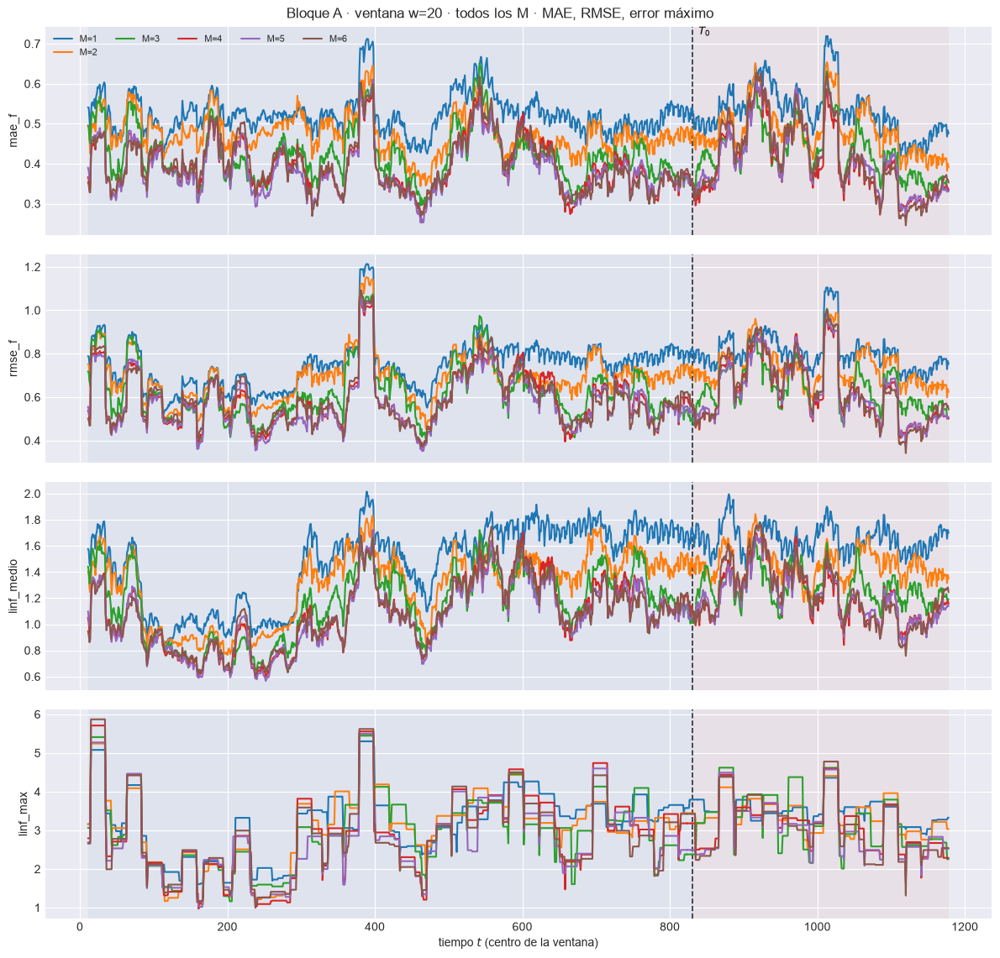

[plot_ventana_movil] inicio (4 pasos)


  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.4277  w=30 test=0.4536


  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.6215  w=30 test=0.6953


  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.181  w=30 test=1.332


  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=3.16  w=30 test=3.498


[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_barrido_M\85_bloqueA_w30.png


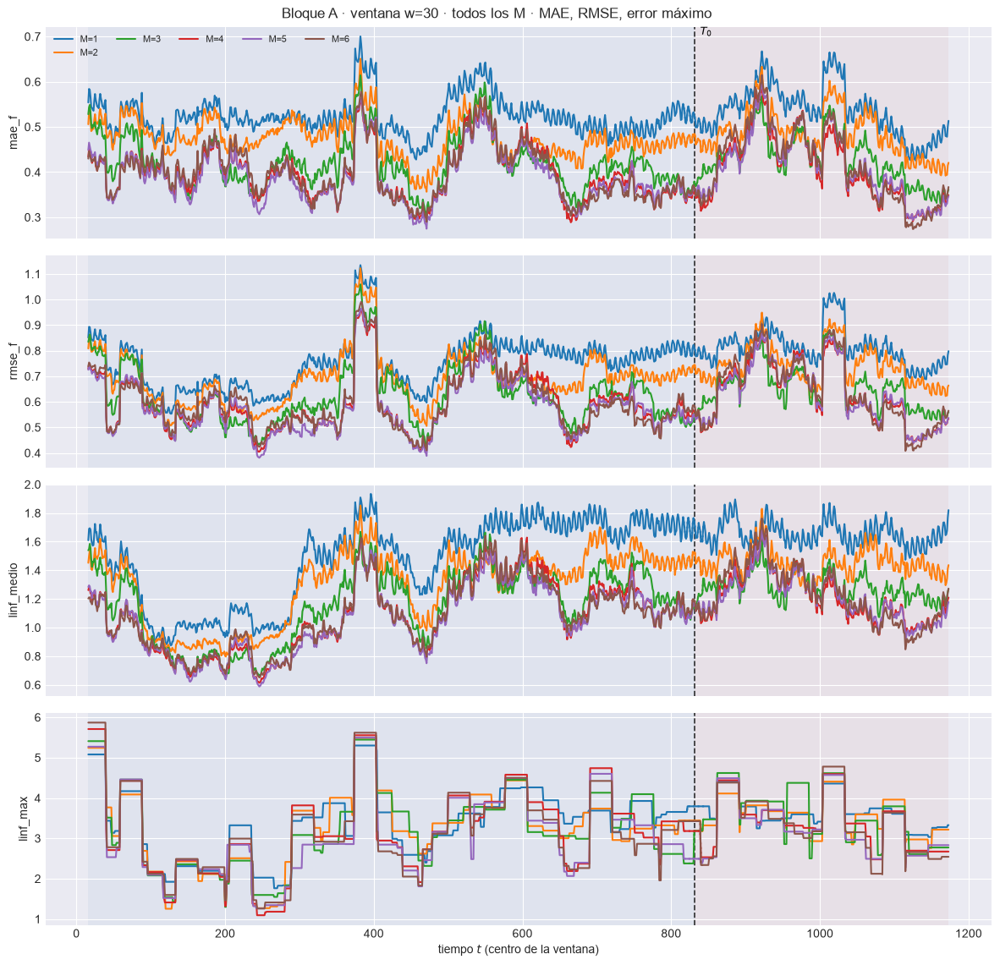

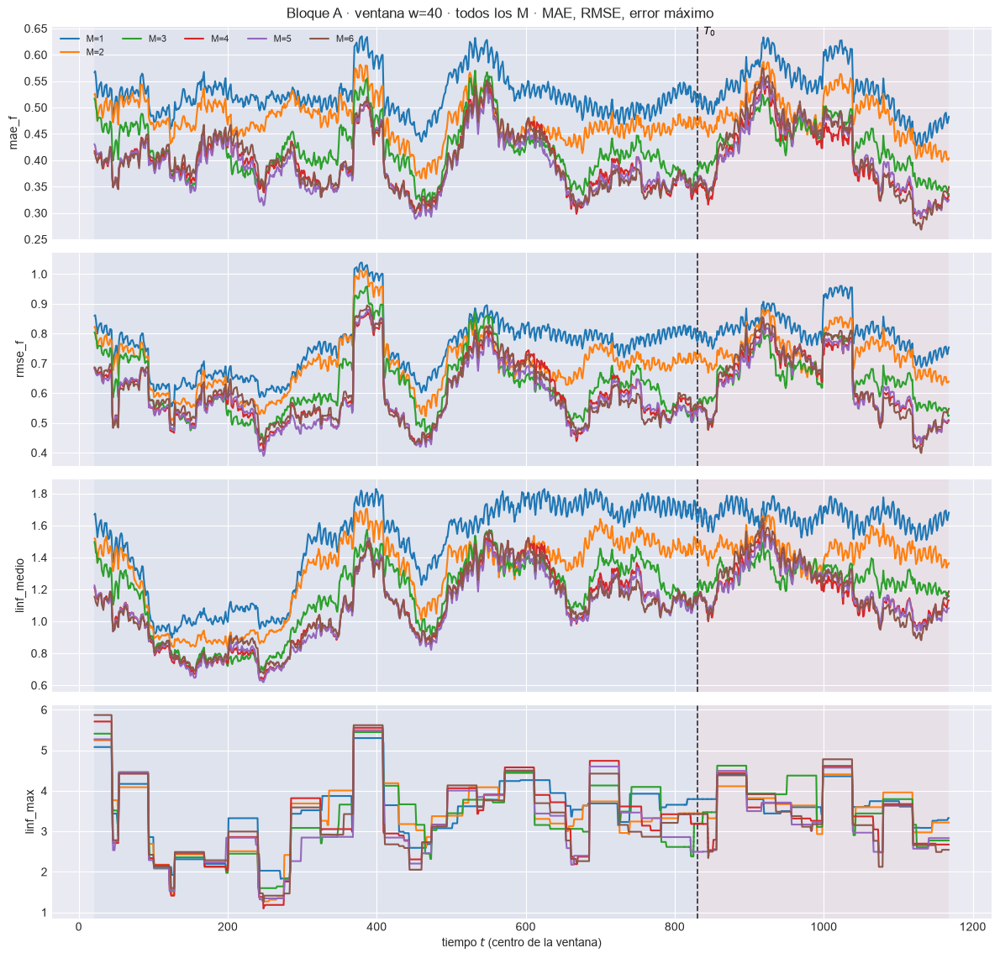

In [7]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?


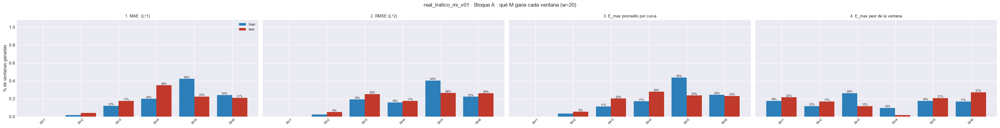

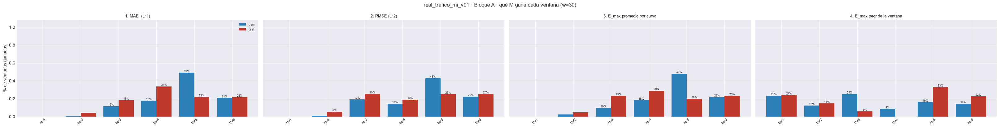

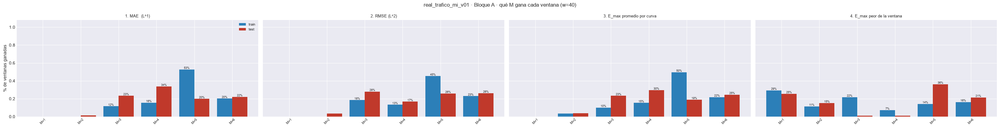

In [8]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

## 5. Bloque B: intervalos de predicción, en una sola vista

Cuatro cifras del intervalo, ninguna "primaria" en esta vista -el Winkler es
la única regla de puntuación propia y por eso es la que ordena modelos cuando
hace falta ordenar, pero aquí se muestran las cuatro juntas-:

| | qué es | de qué es |
|---|---|---|
| **Winkler** | interval score | penaliza ancho Y cobertura a la vez |
| **Cobertura simultánea** | de $w$ curvas, cuántas quedan COMPLETAS dentro de su banda (1/0 por curva) | fracción de CURVAS |
| **Cobertura puntual (PICP)** | de una curva, qué fracción de $\tau$ cae dentro | promedio de esa fracción sobre la ventana |
| **MPIW** | ancho medio de la banda | — |

La cobertura simultánea es SIEMPRE $\le$ la puntual: basta un $\tau$ fuera
para que la curva entera cuente como no cubierta.

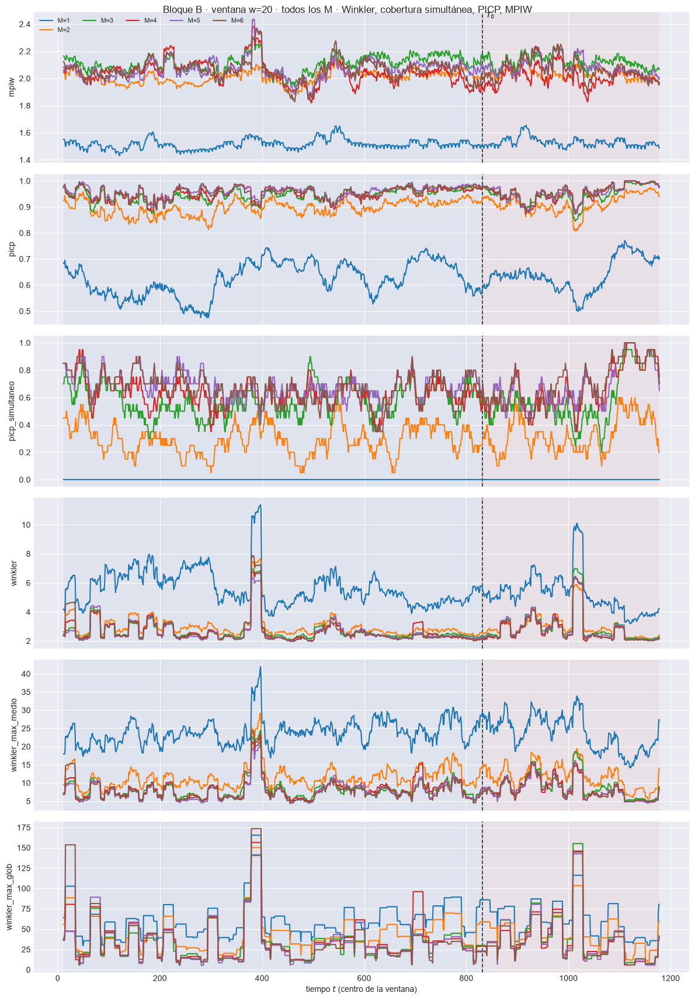

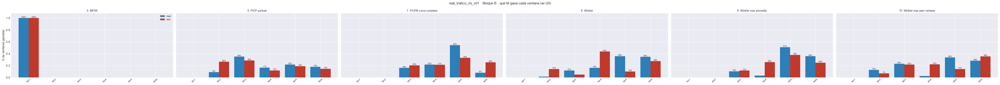

[plot_ventana_movil] inicio (6 pasos)


  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=2.04  w=30 test=2.045


  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9389  w=30 test=0.9375


  3/6 (50.0%) t=0.1s eta=0.1s  picp_simultaneo: w=30 train=0.5667  w=30 test=0.5667


  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=2.667  w=30 test=2.869


  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=8.699  w=30 test=9.586


  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=41.29  w=30 test=47.37


[plot_ventana_movil] listo: 6 pasos en 0.7s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_barrido_M\86_bloqueB_w30.png


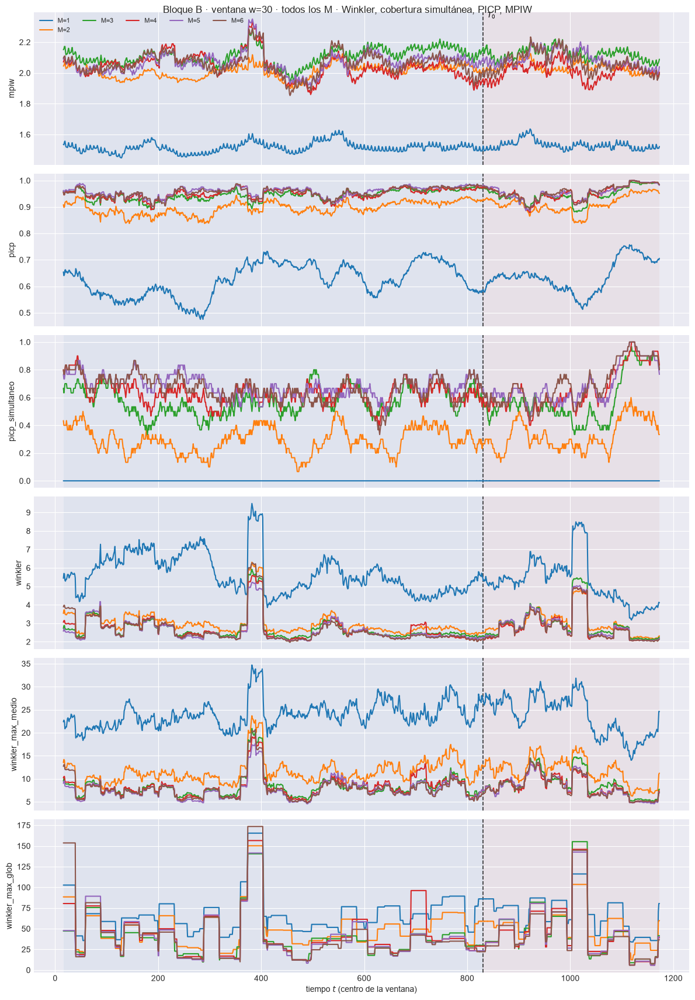

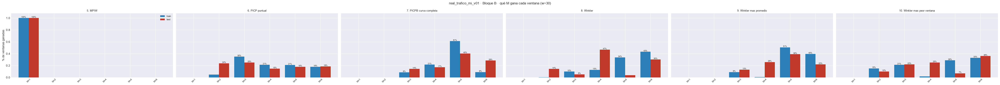

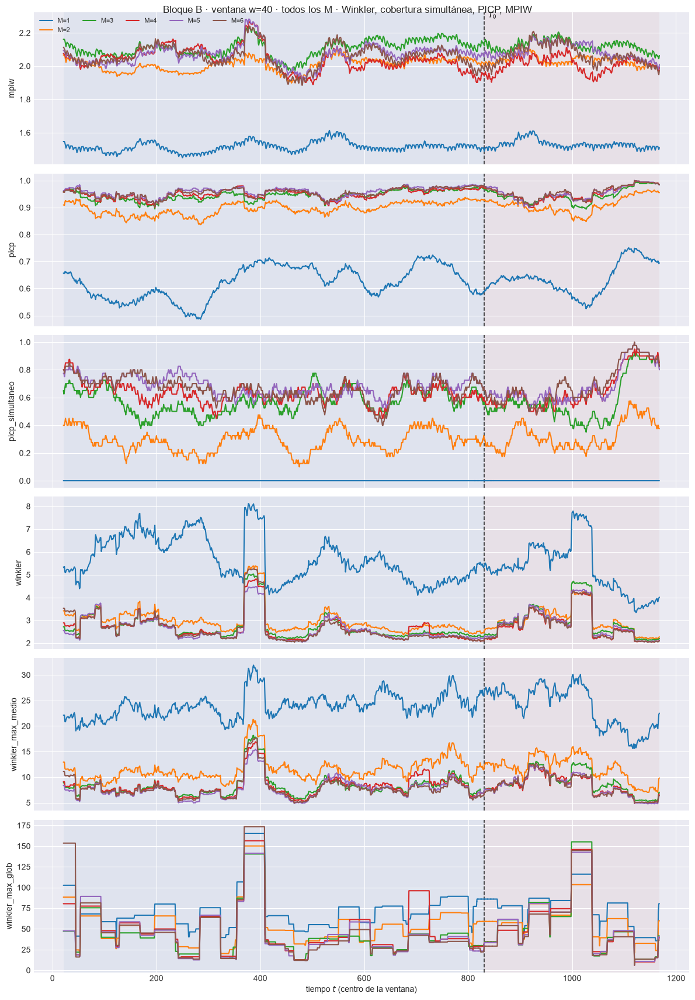

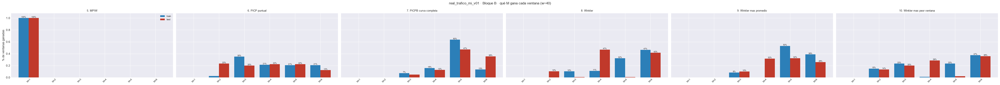

In [9]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

## 6. Muestra de predicciones

Dos vistas: un extracto regular del bloque de **prueba** (para no mezclar con
in-sample), y las ventanas con **peor** valor de `METRICA_PEORES` ([CONFIG]).
En la segunda se agrega la curva **anterior** ($t-1$, gris punteada): es el
primer diagnóstico de POR QUÉ el modelo se equivocó -¿la curva de partida ya
era atípica?-.

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=0.667 rmse=1.053


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=0.667 rmse=0.2499


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=0.542 rmse=0.3932


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=0.750 rmse=1.028


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=0.583 rmse=0.4405


... (4 outputs left out)

  10/12 (83.3%) t=0.0s eta=0.0s  t=1102 [test] cob=0.792 rmse=0.3303


  11/12 (91.7%) t=0.0s eta=0.0s  t=1132 [test] cob=0.792 rmse=0.8294


  12/12 (100.0%) t=0.1s eta=0.0s  t=1162 [test] cob=0.708 rmse=0.9666


[plot_extractos_curvas] listo: 12 pasos en 1.0s  cob media train=nan test=0.646 (nominal 0.95)


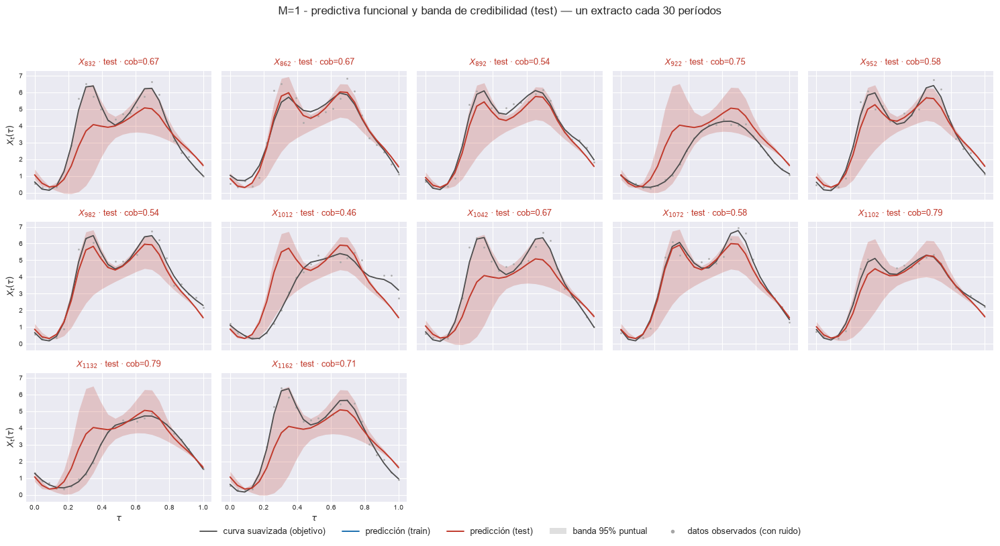

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.9477


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=0.833 rmse=0.2932


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=1.000 rmse=0.3556


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=1.000 rmse=1.029


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=0.833 rmse=0.275


... (4 outputs left out)

  10/12 (83.3%) t=0.2s eta=0.0s  t=1102 [test] cob=0.917 rmse=0.2338


  11/12 (91.7%) t=0.2s eta=0.0s  t=1132 [test] cob=1.000 rmse=0.7856


  12/12 (100.0%) t=0.2s eta=0.0s  t=1162 [test] cob=1.000 rmse=0.6171


[plot_extractos_curvas] listo: 12 pasos en 1.1s  cob media train=nan test=0.931 (nominal 0.95)


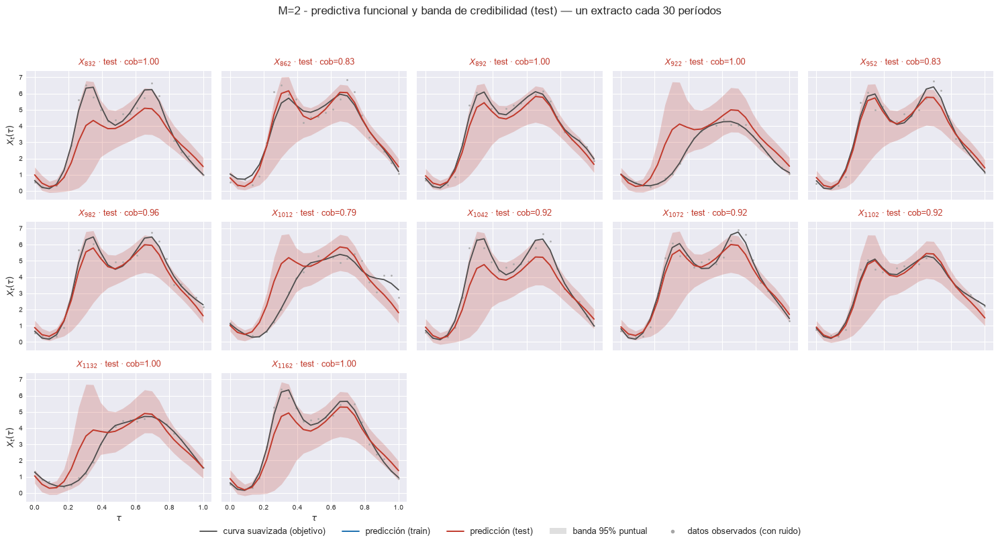

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.5717


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=1.000 rmse=0.3188


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=1.000 rmse=0.2751


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=1.000 rmse=0.8371


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=0.917 rmse=0.2372


... (4 outputs left out)

  10/12 (83.3%) t=0.0s eta=0.0s  t=1102 [test] cob=1.000 rmse=0.2102


  11/12 (91.7%) t=0.0s eta=0.0s  t=1132 [test] cob=1.000 rmse=0.5745


  12/12 (100.0%) t=0.0s eta=0.0s  t=1162 [test] cob=1.000 rmse=0.3939


[plot_extractos_curvas] listo: 12 pasos en 1.0s  cob media train=nan test=0.965 (nominal 0.95)


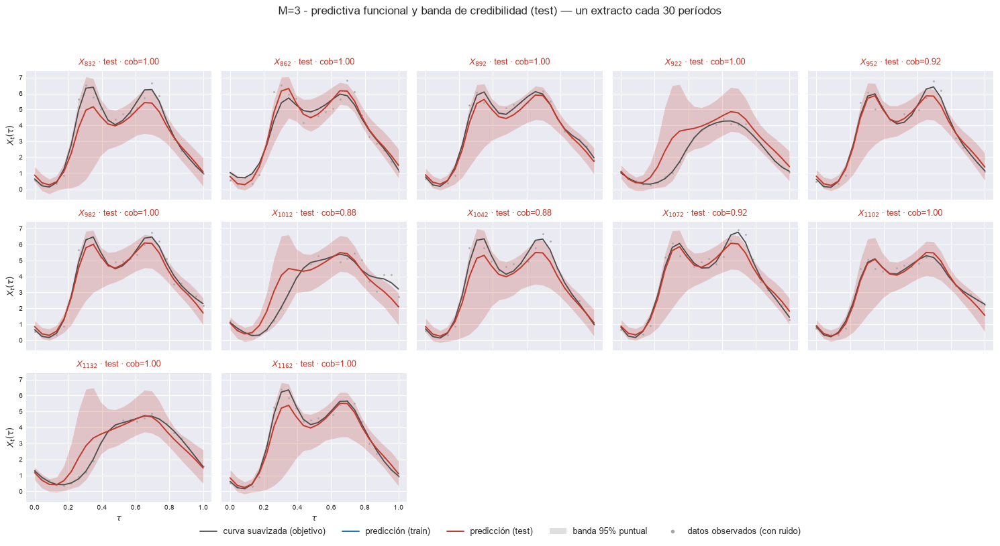

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.2109


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=0.875 rmse=0.3029


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=1.000 rmse=0.2318


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=1.000 rmse=1.07


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=1.000 rmse=0.2237


... (4 outputs left out)

  10/12 (83.3%) t=0.0s eta=0.0s  t=1102 [test] cob=1.000 rmse=0.2256


  11/12 (91.7%) t=0.0s eta=0.0s  t=1132 [test] cob=1.000 rmse=0.6327


  12/12 (100.0%) t=0.1s eta=0.0s  t=1162 [test] cob=1.000 rmse=0.2541


[plot_extractos_curvas] listo: 12 pasos en 1.1s  cob media train=nan test=0.979 (nominal 0.95)


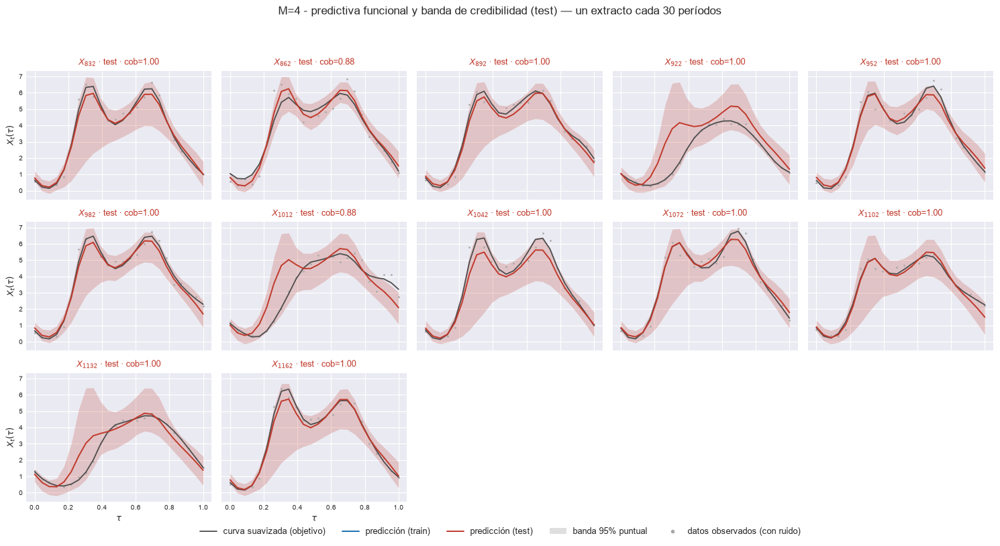

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.2682


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=1.000 rmse=0.3198


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=1.000 rmse=0.2156


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=1.000 rmse=1.046


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=1.000 rmse=0.2106


... (4 outputs left out)

  10/12 (83.3%) t=0.0s eta=0.0s  t=1102 [test] cob=1.000 rmse=0.2224


  11/12 (91.7%) t=0.0s eta=0.0s  t=1132 [test] cob=1.000 rmse=0.6086


  12/12 (100.0%) t=0.0s eta=0.0s  t=1162 [test] cob=1.000 rmse=0.2514


[plot_extractos_curvas] listo: 12 pasos en 1.0s  cob media train=nan test=0.990 (nominal 0.95)


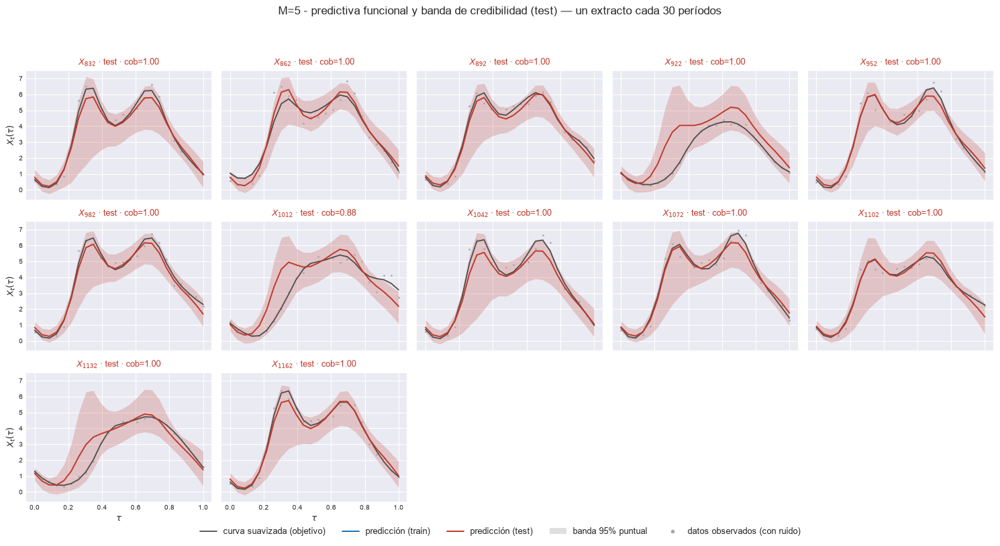

[plot_extractos_curvas] inicio (12 pasos)


  1/12 ( 8.3%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.3744


  2/12 (16.7%) t=0.0s eta=0.0s  t=862 [test] cob=0.833 rmse=0.366


  3/12 (25.0%) t=0.0s eta=0.0s  t=892 [test] cob=1.000 rmse=0.225


  4/12 (33.3%) t=0.0s eta=0.0s  t=922 [test] cob=1.000 rmse=1.032


  5/12 (41.7%) t=0.0s eta=0.0s  t=952 [test] cob=0.958 rmse=0.1988


... (4 outputs left out)

  10/12 (83.3%) t=0.0s eta=0.0s  t=1102 [test] cob=1.000 rmse=0.2356


  11/12 (91.7%) t=0.0s eta=0.0s  t=1132 [test] cob=1.000 rmse=0.7447


  12/12 (100.0%) t=0.0s eta=0.0s  t=1162 [test] cob=1.000 rmse=0.3152


[plot_extractos_curvas] listo: 12 pasos en 1.0s  cob media train=nan test=0.976 (nominal 0.95)


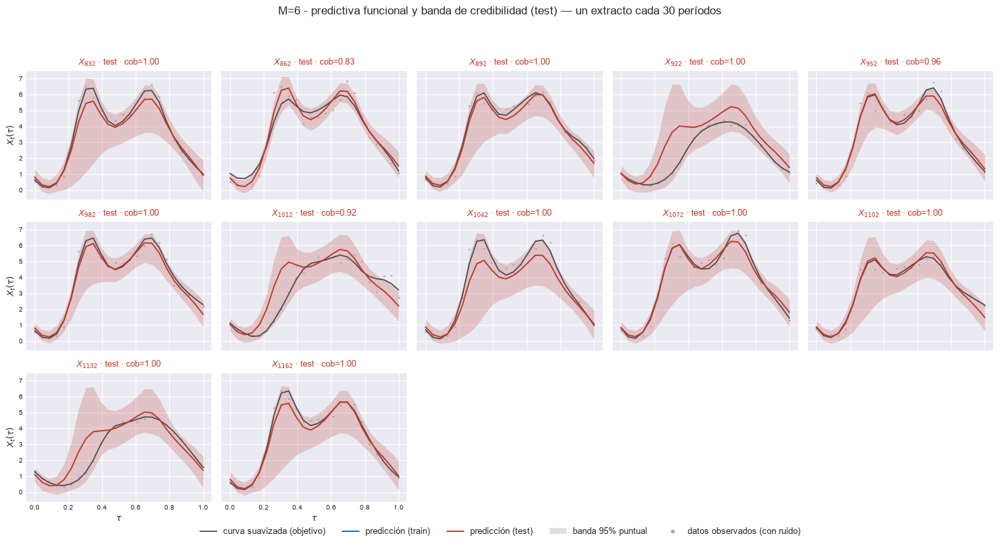

In [10]:
# Extractos regulares, SOLO del bloque de prueba.
mask_test = ~es_train
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[mask_test], e["X_pred"][mask_test], e["li_f"][mask_test], e["ls_f"][mask_test],
        grilla, T0, t=t_orig[mask_test], cada=CADA, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[mask_test],
        title=f"M={M} - predictiva funcional y banda de credibilidad (test)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=0.667 rmse=0.2517


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.583 rmse=0.449


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.500 rmse=1.426


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.750 rmse=0.874


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=0.667 rmse=1.053


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=0.500 rmse=0.4242


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=0.667 rmse=0.3068


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.625 test=0.611 (nominal 0.95)


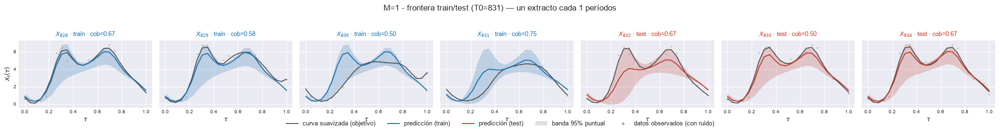

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=0.917 rmse=0.2543


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.958 rmse=0.4551


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.833 rmse=1.251


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.917 rmse=0.4798


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.9477


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=0.875 rmse=0.3286


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=1.000 rmse=0.3693


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.906 test=0.958 (nominal 0.95)


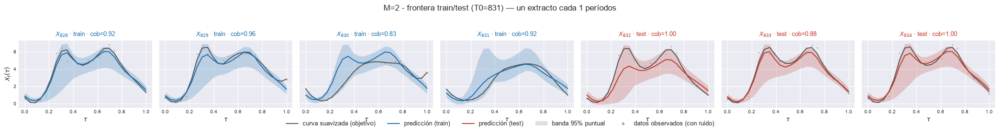

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=1.000 rmse=0.1898


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.958 rmse=0.3866


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.917 rmse=0.9671


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.958 rmse=0.4424


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.5717


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=0.958 rmse=0.2726


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=1.000 rmse=0.2857


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.958 test=0.986 (nominal 0.95)


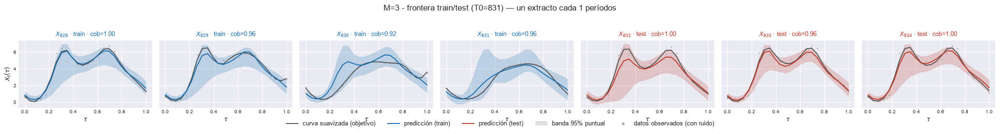

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=1.000 rmse=0.1726


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.958 rmse=0.342


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.917 rmse=0.9092


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.958 rmse=0.3188


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.2109


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=1.000 rmse=0.2666


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=1.000 rmse=0.2657


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.958 test=1.000 (nominal 0.95)


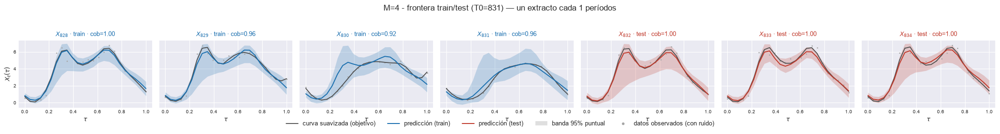

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=1.000 rmse=0.1626


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.958 rmse=0.3744


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.917 rmse=0.9118


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.958 rmse=0.3582


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.2682


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=1.000 rmse=0.2645


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=1.000 rmse=0.2714


[plot_extractos_curvas] listo: 7 pasos en 0.8s  cob media train=0.958 test=1.000 (nominal 0.95)


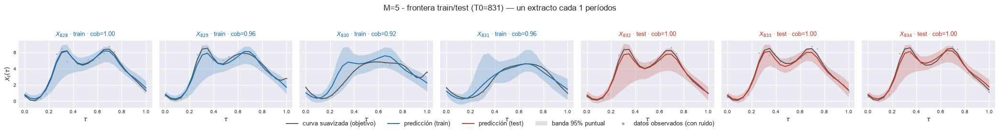

[plot_extractos_curvas] inicio (7 pasos)


  1/7 (14.3%) t=0.0s eta=0.0s  t=828 [train] cob=1.000 rmse=0.1473


  2/7 (28.6%) t=0.0s eta=0.0s  t=829 [train] cob=0.958 rmse=0.3421


  3/7 (42.9%) t=0.0s eta=0.0s  t=830 [train] cob=0.917 rmse=0.8904


  4/7 (57.1%) t=0.0s eta=0.0s  t=831 [train] cob=0.958 rmse=0.4538


  5/7 (71.4%) t=0.0s eta=0.0s  t=832 [test] cob=1.000 rmse=0.3744


  6/7 (85.7%) t=0.0s eta=0.0s  t=833 [test] cob=1.000 rmse=0.2396


  7/7 (100.0%) t=0.0s eta=0.0s  t=834 [test] cob=1.000 rmse=0.2493


[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.958 test=1.000 (nominal 0.95)


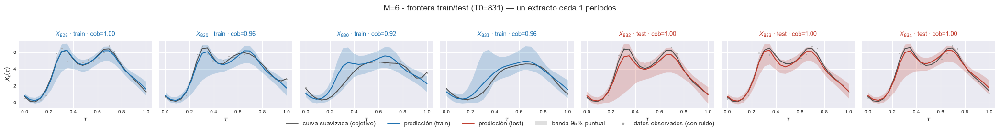

In [11]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=1] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[1005, 1034]  rmse_f=1.026070


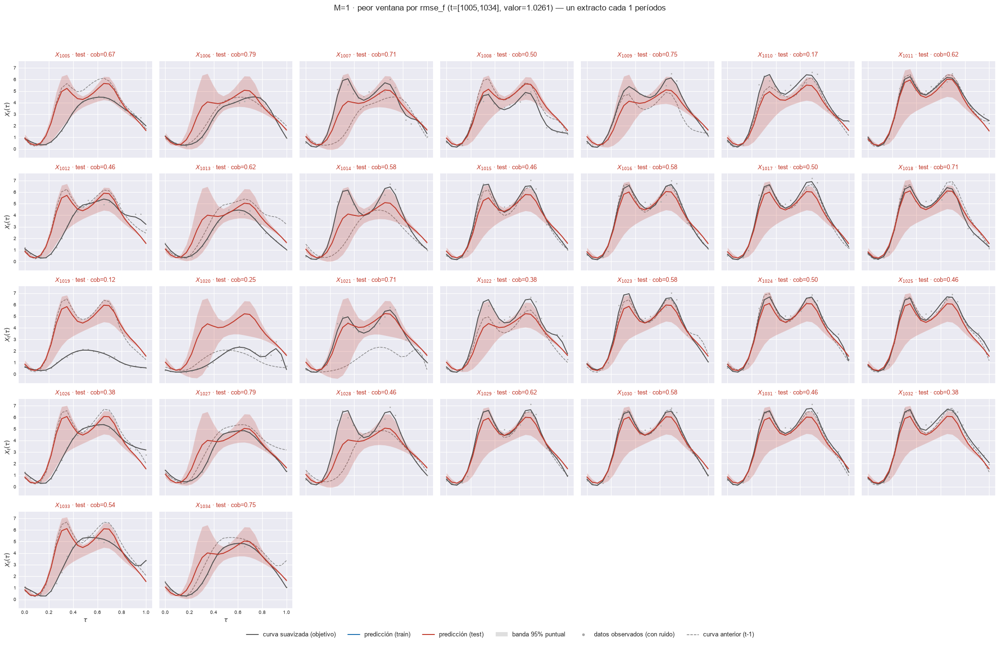

    t=[999, 1028]  rmse_f=1.024841


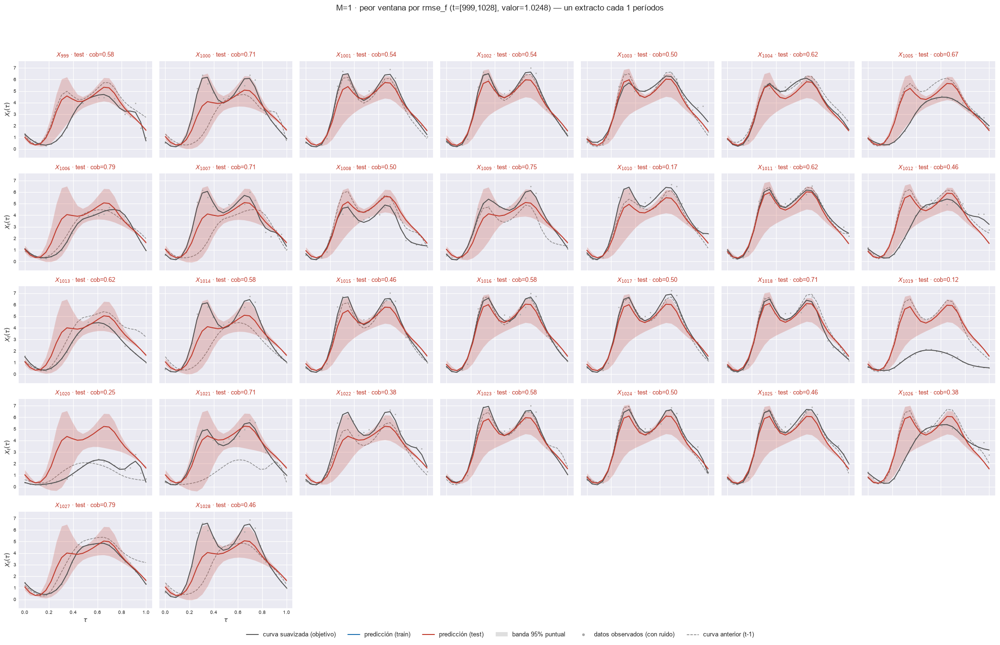

    t=[1006, 1035]  rmse_f=1.018916


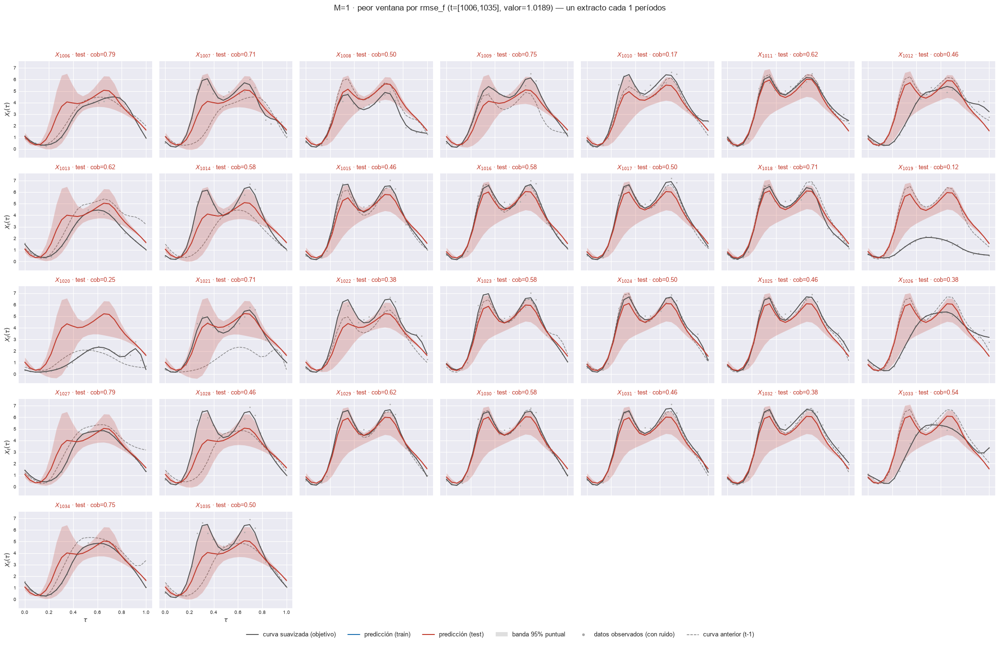

    t=[1004, 1033]  rmse_f=1.017317


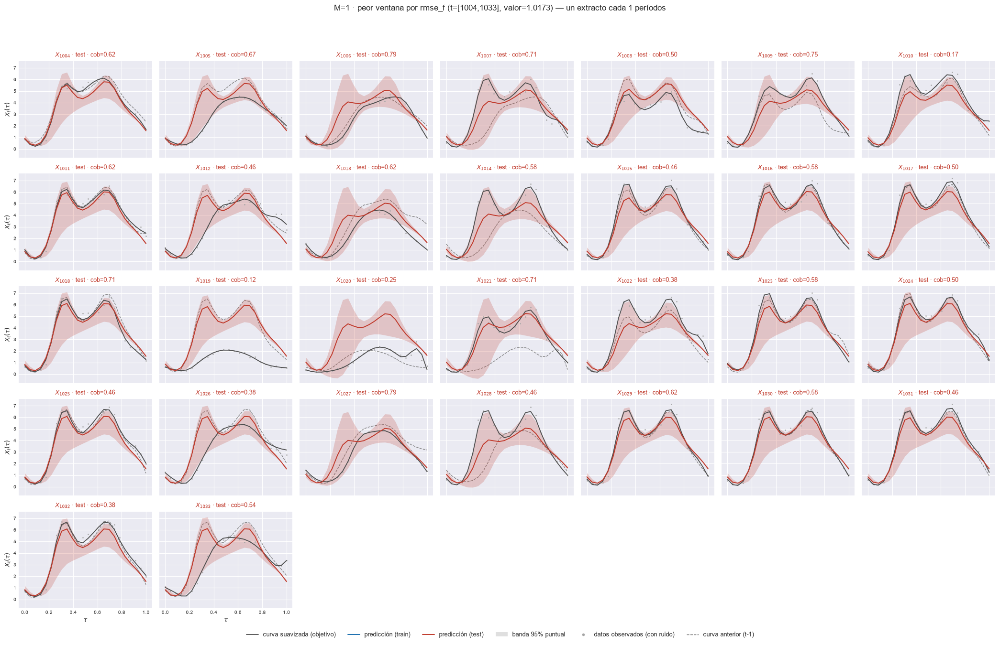

    t=[998, 1027]  rmse_f=1.006586


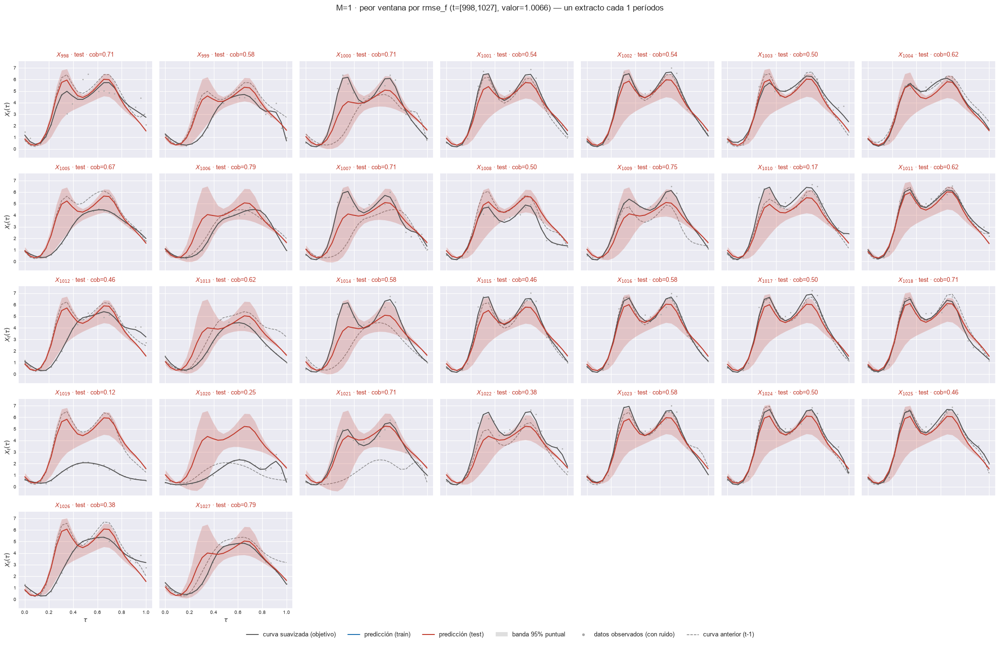

[M=2] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[908, 937]  rmse_f=0.948915


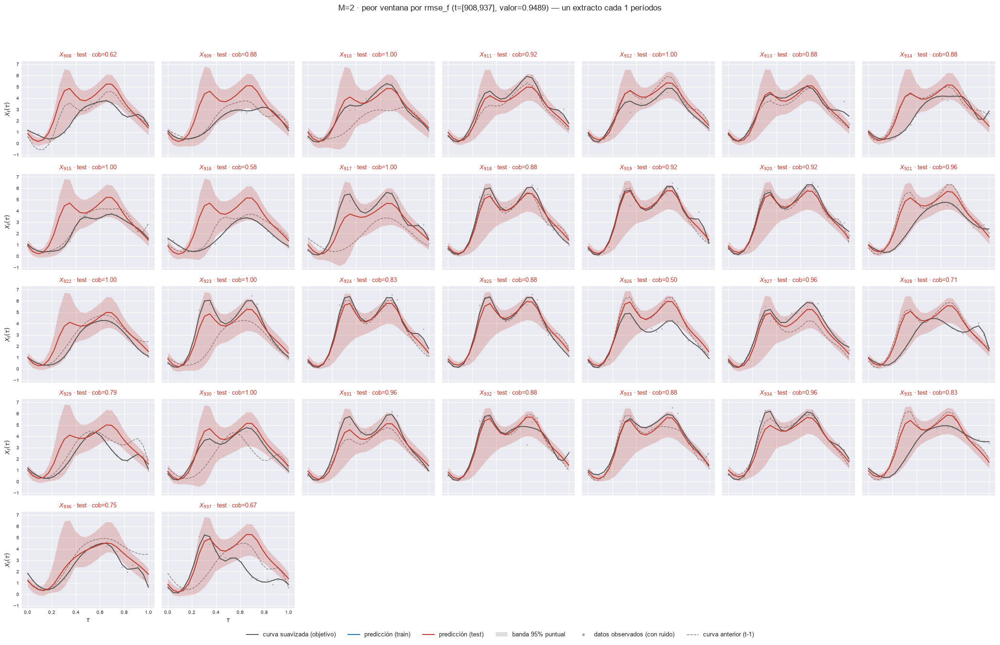

    t=[999, 1028]  rmse_f=0.923189


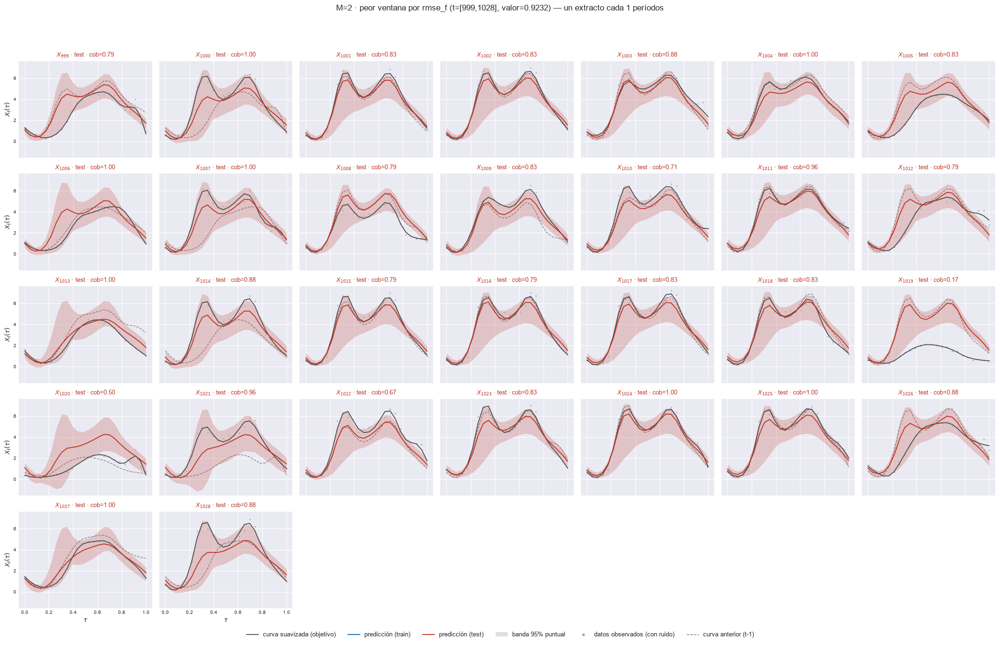

    t=[907, 936]  rmse_f=0.916955


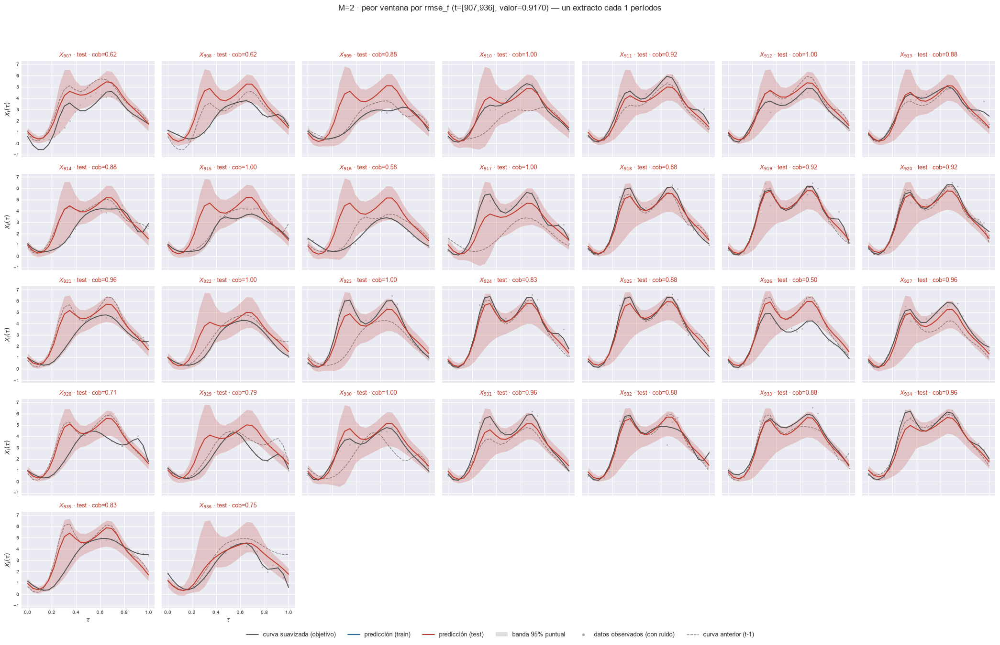

    t=[906, 935]  rmse_f=0.912734


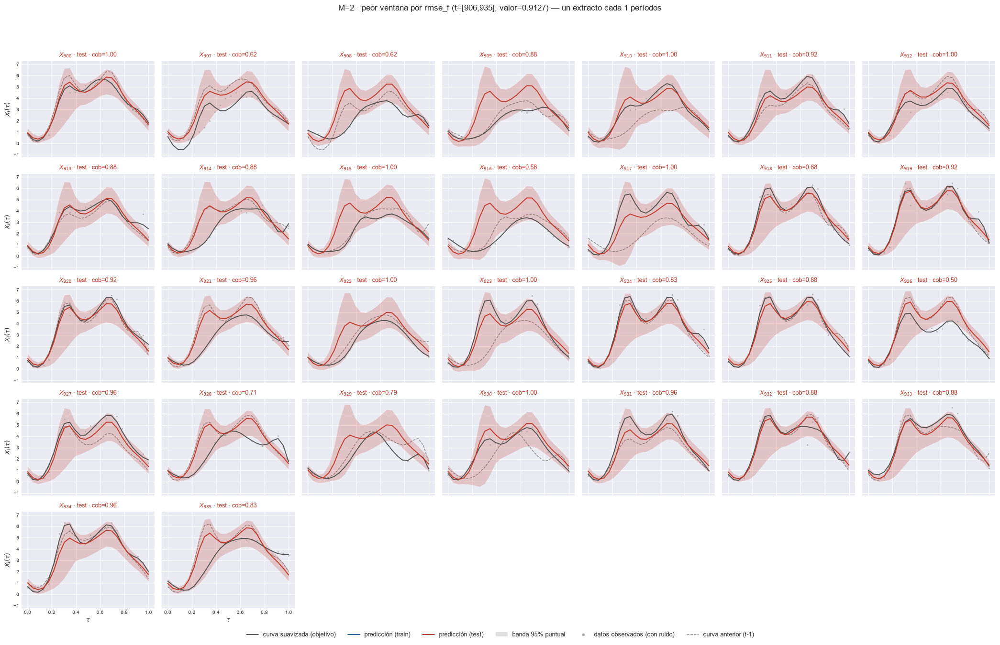

    t=[909, 938]  rmse_f=0.909548


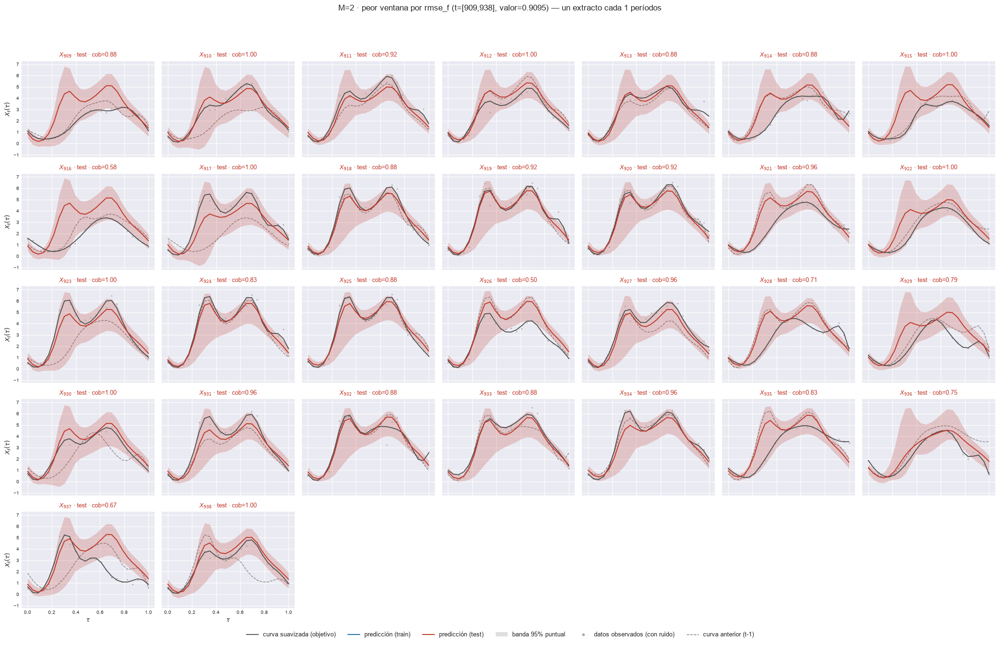

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[999, 1028]  rmse_f=0.881077


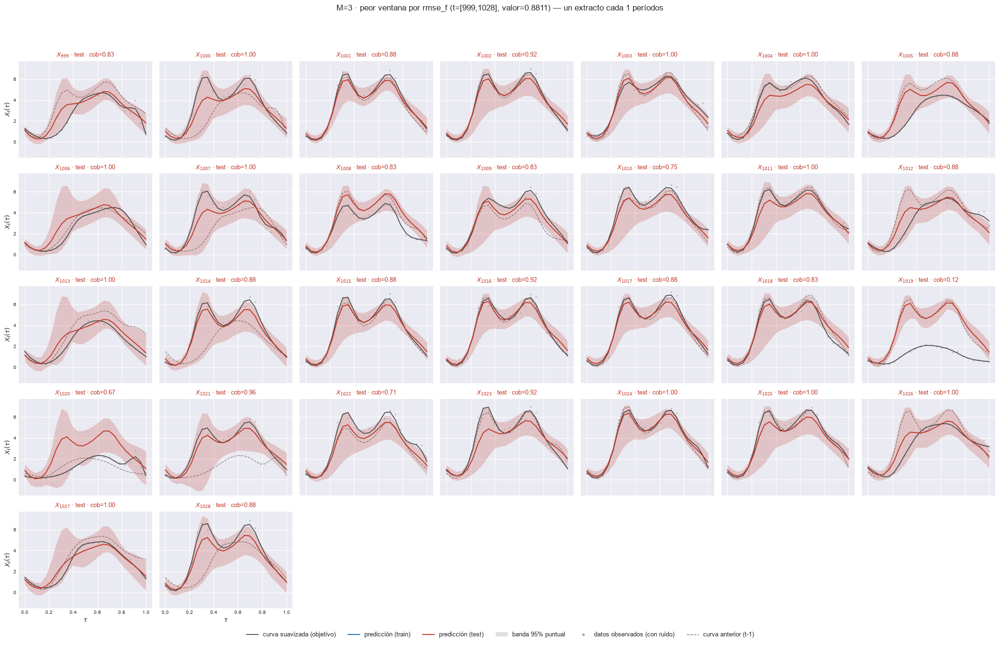

    t=[998, 1027]  rmse_f=0.873838


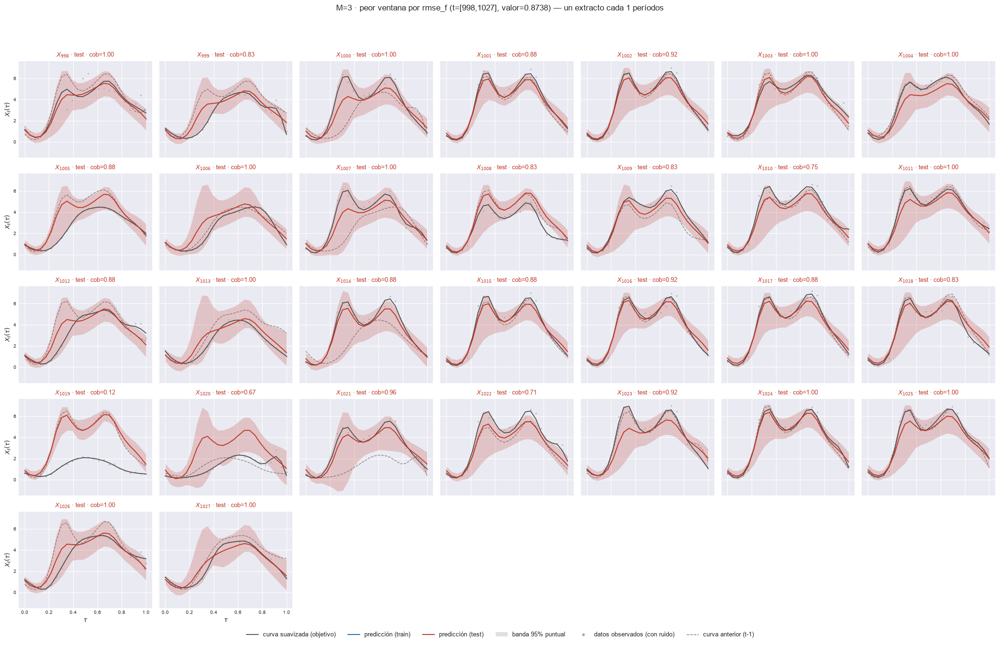

    t=[997, 1026]  rmse_f=0.872880


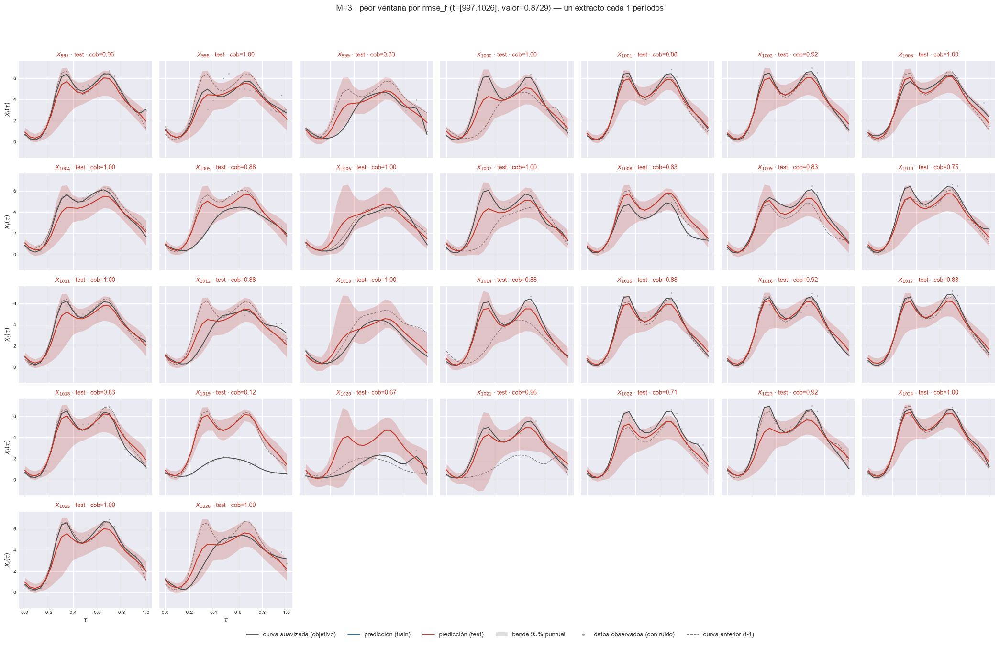

    t=[1004, 1033]  rmse_f=0.872446


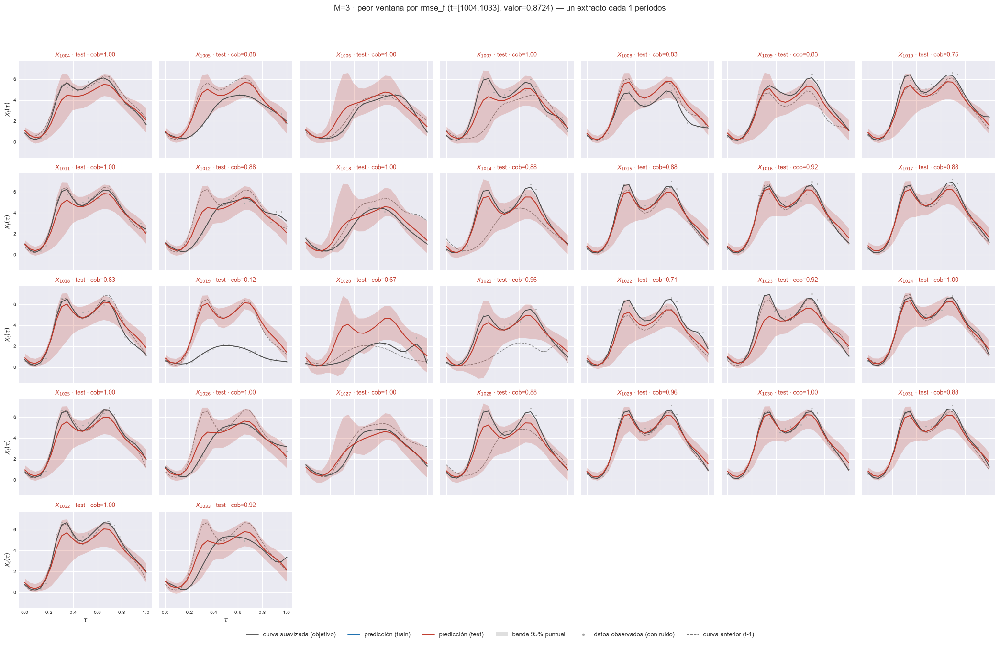

    t=[1000, 1029]  rmse_f=0.872116


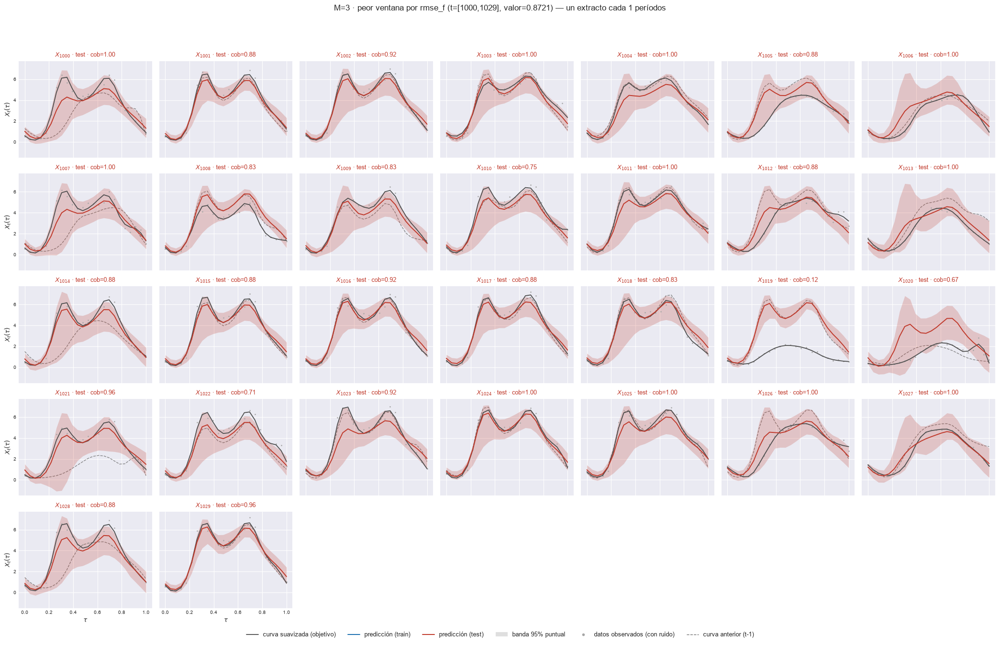

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[908, 937]  rmse_f=0.882965


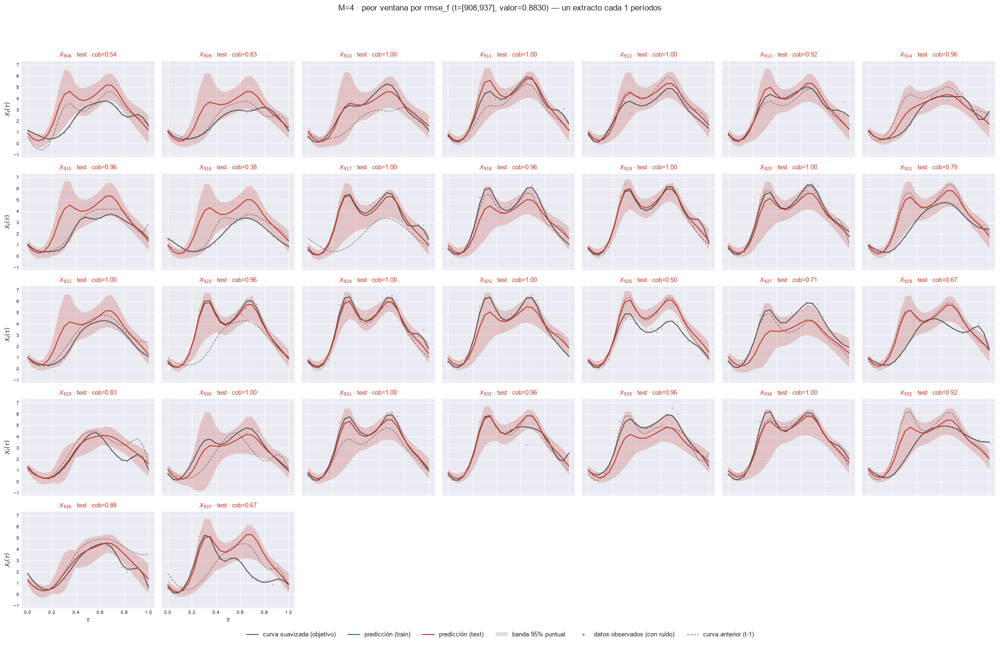

    t=[909, 938]  rmse_f=0.857850


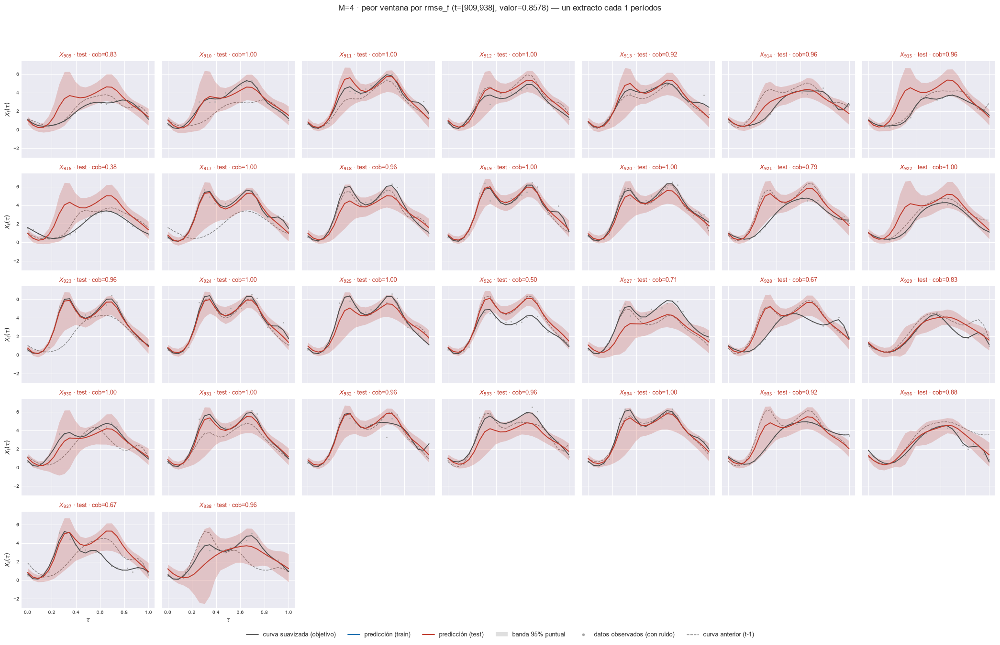

    t=[899, 928]  rmse_f=0.857668


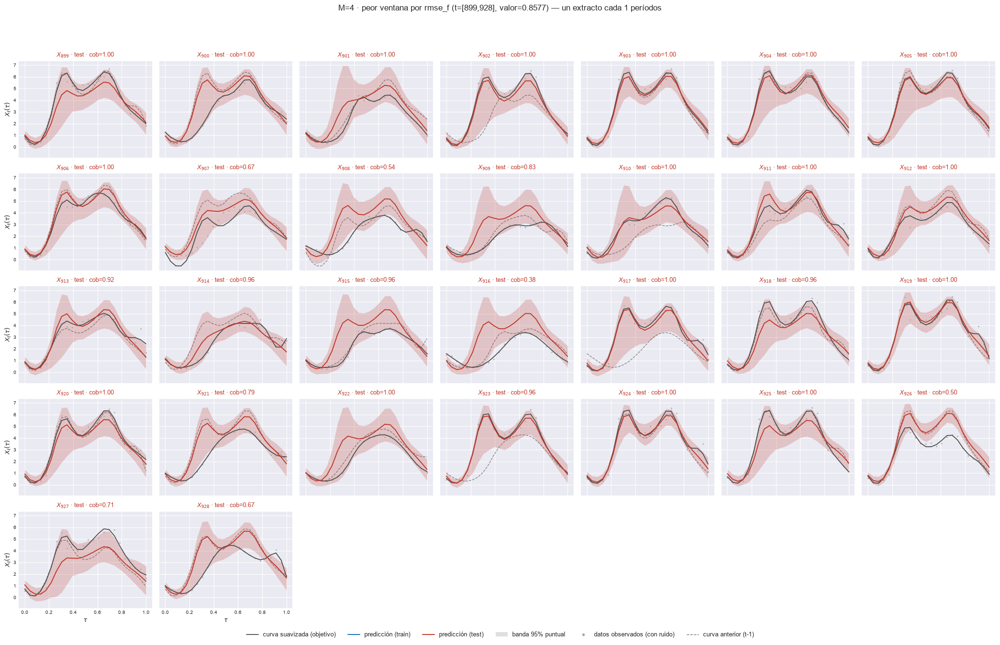

    t=[900, 929]  rmse_f=0.855097


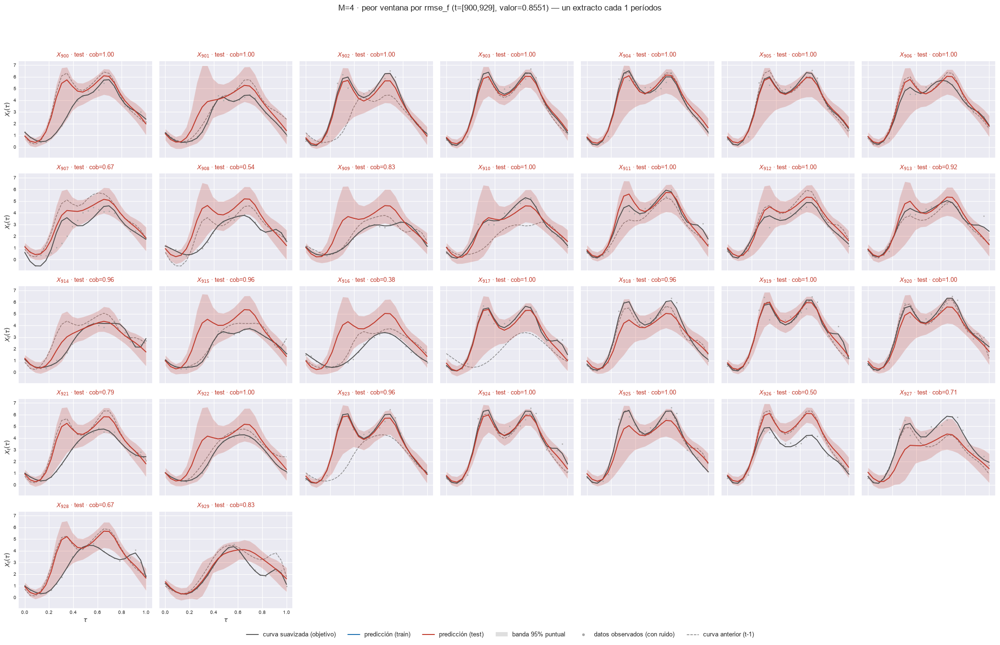

    t=[1004, 1033]  rmse_f=0.850748


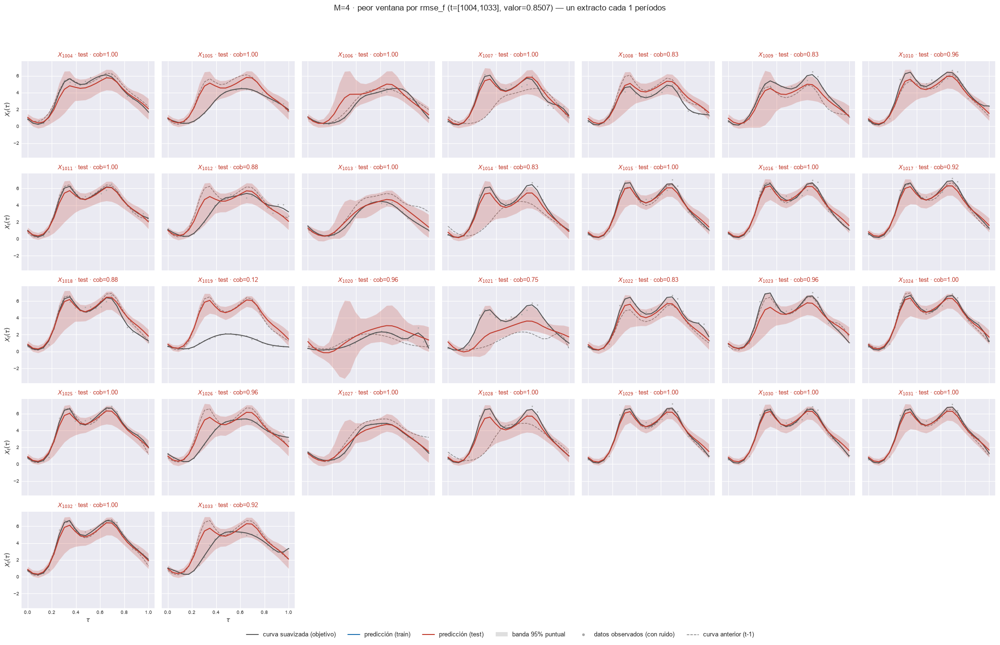

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[908, 937]  rmse_f=0.880928


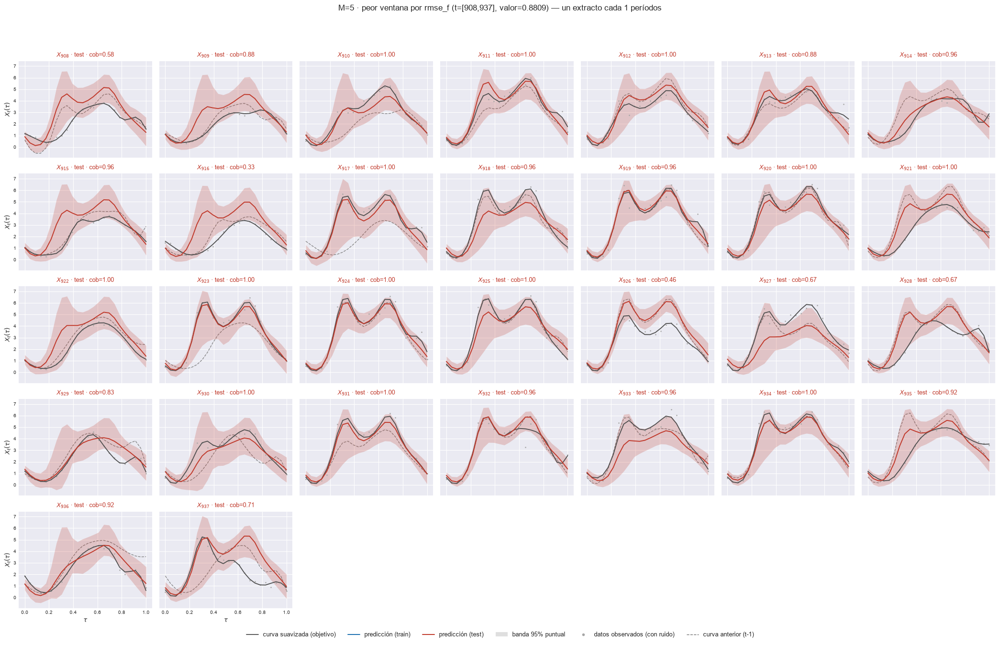

    t=[909, 938]  rmse_f=0.860815


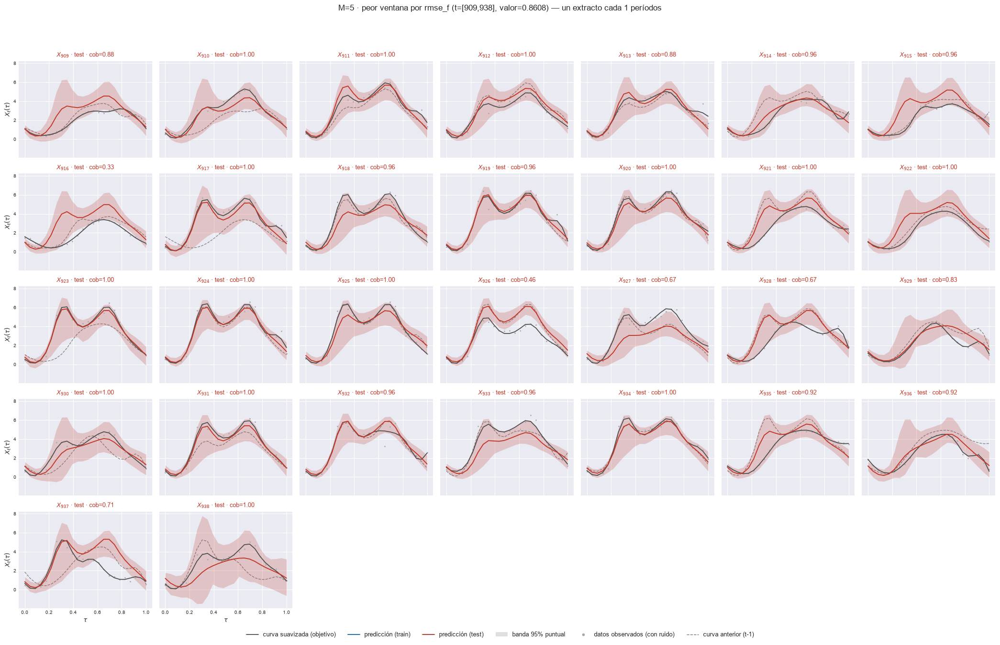

    t=[999, 1028]  rmse_f=0.857088


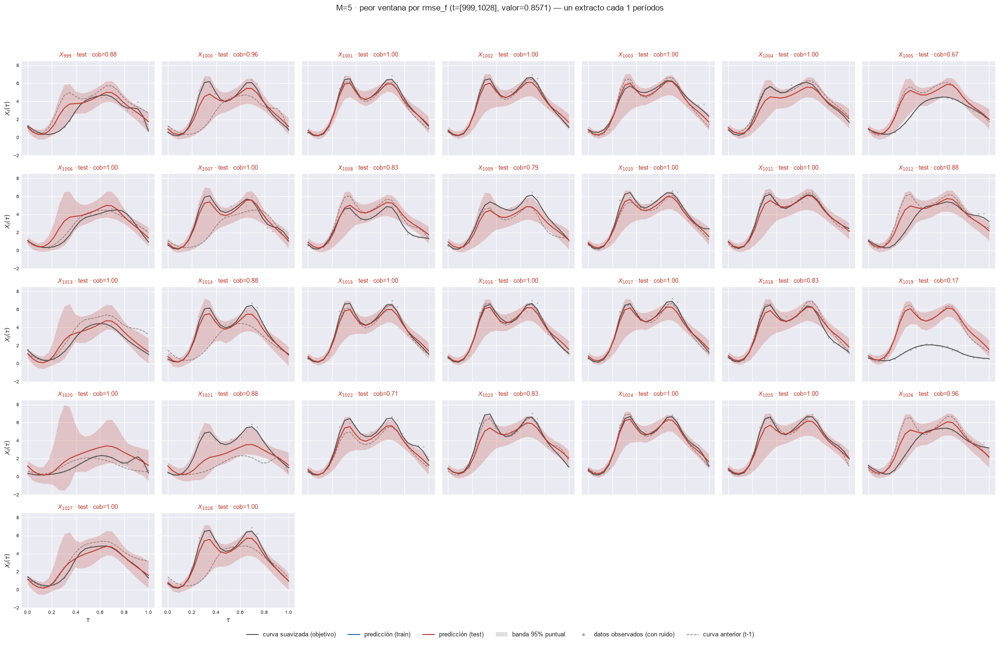

    t=[1004, 1033]  rmse_f=0.856712


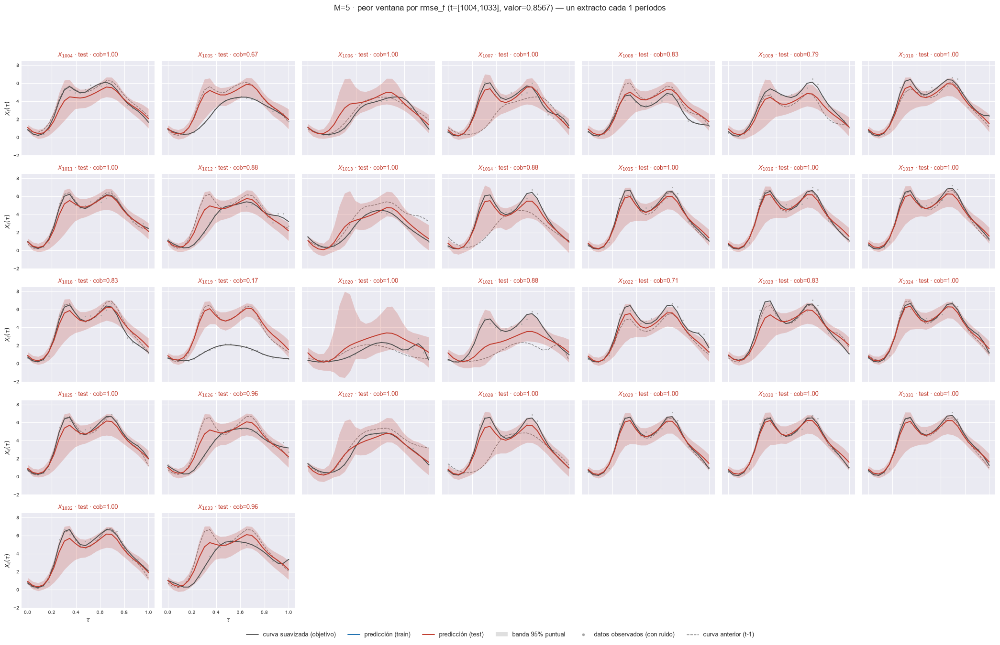

    t=[998, 1027]  rmse_f=0.854196


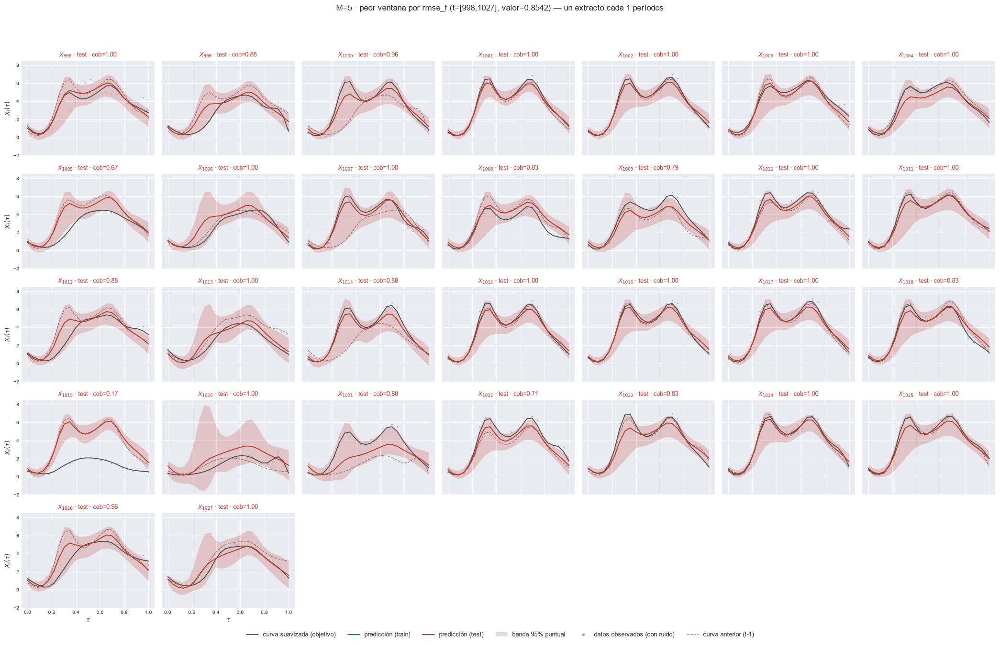

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[908, 937]  rmse_f=0.904476


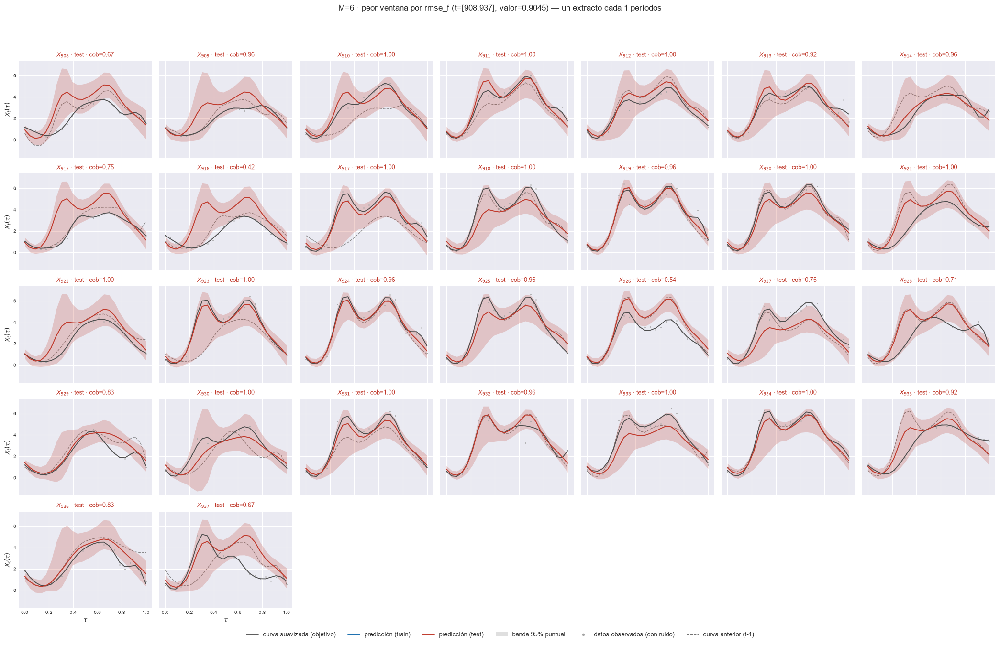

    t=[1004, 1033]  rmse_f=0.881458


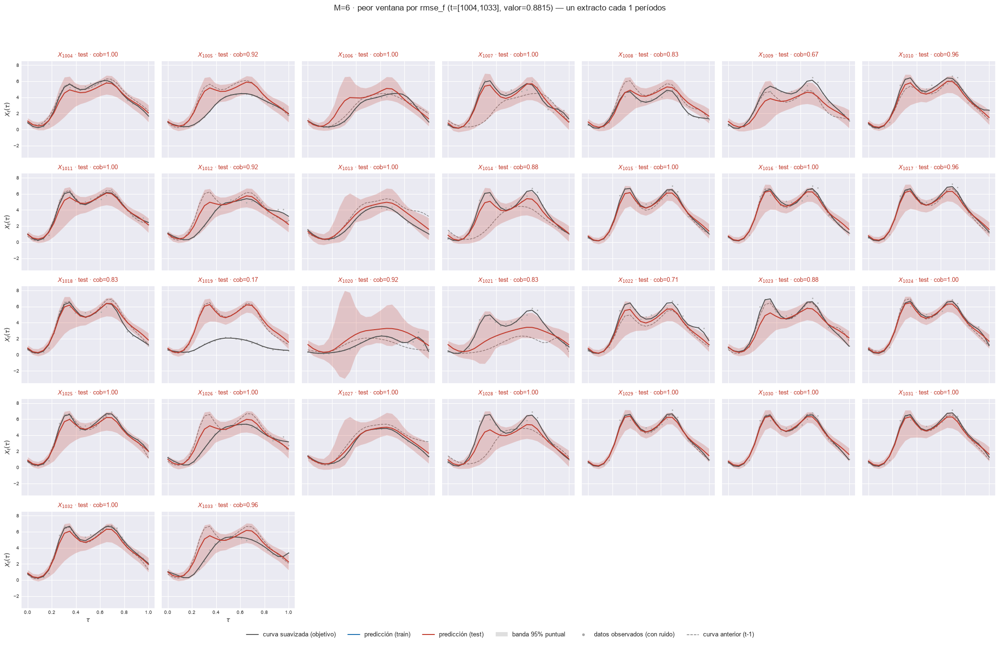

    t=[1005, 1034]  rmse_f=0.880706


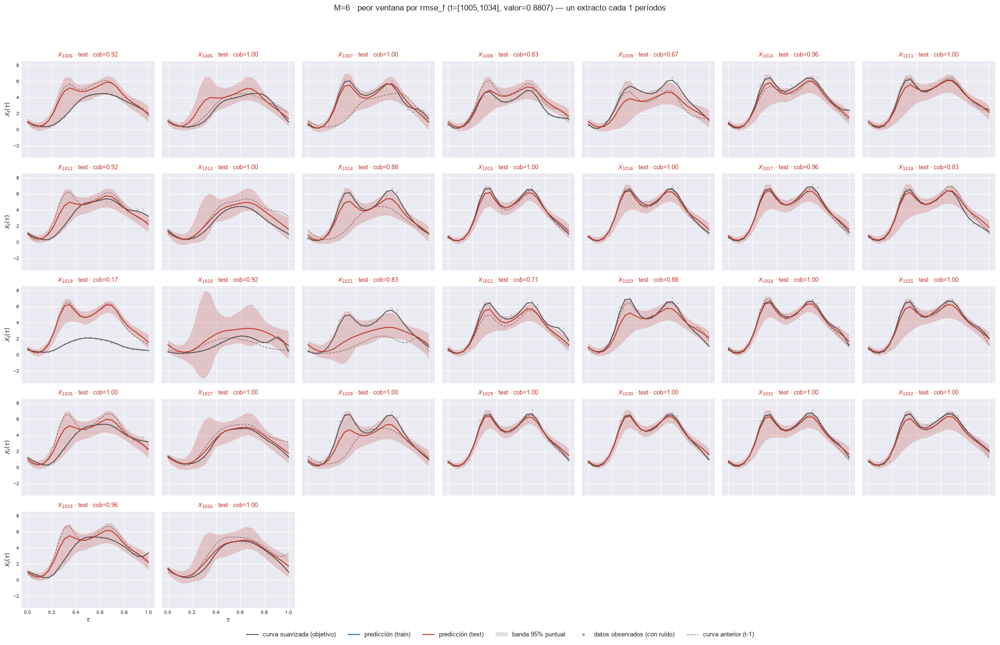

    t=[999, 1028]  rmse_f=0.879721


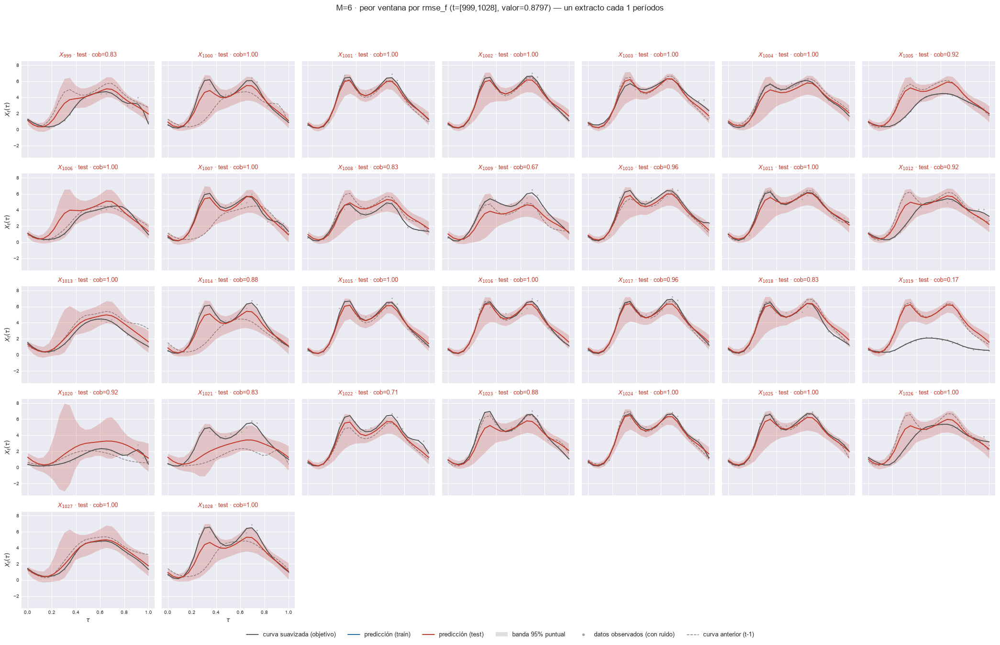

    t=[909, 938]  rmse_f=0.878321


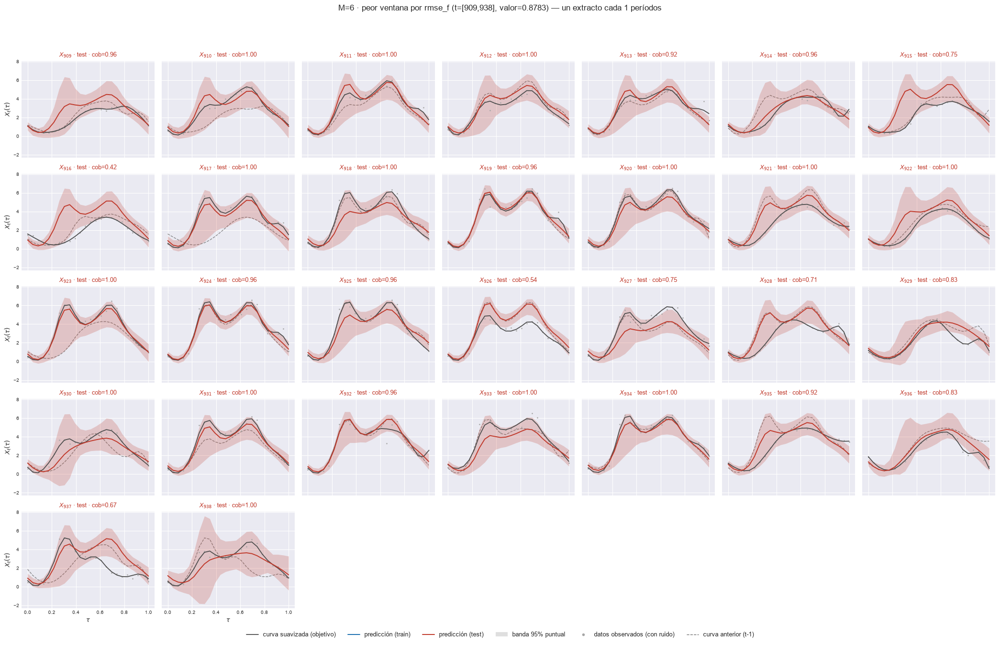

In [12]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

Qué covariables (rezago 1 de cada componente, propia y cruzadas) selecciona el modelo en cada componente. Con datos reales no hay estructura verdadera contra la cual contrastar: se reporta el PIP global y su dispersión entre cadenas.


In [13]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (1 pasos)


  1/1 (100.0%) t=0.0s eta=0.0s  FPC 1: 1 cadenas, 1 variables, PIP en [1.000, 1.000]


[matriz_pip] listo: 1 pasos en 0.0s  tabla 1x2


[M=1] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd
variable,,
fpc_1_lag1,1.000,0.000


[matriz_pip] inicio (2 pasos)


... (35 outputs left out)

  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 1 cadenas, 6 variables, PIP en [0.090, 1.000]


[matriz_pip] listo: 6 pasos en 0.0s  tabla 6x12


[M=6] dispersion maxima entre cadenas: 0.000   OK las cadenas coinciden


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_2_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.976,0.000,0.220,0.000,0.090,0.000
fpc_3_lag1,1.000,0.000,1.000,0.000,1.000,0.000,0.978,0.000,1.000,0.000,0.274,0.000
fpc_4_lag1,1.000,0.000,0.305,0.000,0.179,0.000,1.000,0.000,1.000,0.000,1.000,0.000
fpc_5_lag1,0.713,0.000,1.000,0.000,0.422,0.000,0.131,0.000,1.000,0.000,0.180,0.000
fpc_6_lag1,0.812,0.000,0.155,0.000,0.160,0.000,0.150,0.000,0.191,0.000,1.000,0.000


## 8. Cuadro resumen: mínimo, máximo y promedio

La ventana móvil genera una SERIE por métrica, no una cifra. Esta tabla es la
lectura resumida de esa serie: mínimo, máximo y promedio, por bloque
train/test, excluyendo las ventanas que cruzan $T_0$ -su cifra mezcla dentro y
fuera de muestra-. Cubre las 7 métricas de los Bloques A y B; ninguna se
destaca sobre las demás.

In [14]:
# Los dos objetivos en la misma tabla, con la columna que declara cuál.
for M in M_OK:
    resumen = resumen_metricas(EST[M], M, DIS, ORIG)
    display(resumen.style.format({"minimo": "{:.6f}", "maximo": "{:.6f}", "promedio": "{:.6f}"})
            .set_caption(f"M={M} · mínimo / máximo / promedio por ventana "
                         f"(w={W_REF}, sin cruzar T0) · nivel funcional"))

resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)
# Vista rápida: un solo objetivo (el primario del Bloque A); el CSV tiene los dos.
display(resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")]
        .pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=1] curva_suavizada      PICP puntual test = 0.6396 (nominal 0.95)  ·  PICP simultaneo test = 0.0000
[M=1] representacion_fpca  PICP puntual test = 0.9573 (nominal 0.95)  ·  PICP simultaneo test = 0.9573


[M=2] curva_suavizada      PICP puntual test = 0.9098 (nominal 0.95)  ·  PICP simultaneo test = 0.3295
[M=2] representacion_fpca  PICP puntual test = 0.9635 (nominal 0.95)  ·  PICP simultaneo test = 0.8586


[M=3] curva_suavizada      PICP puntual test = 0.9445 (nominal 0.95)  ·  PICP simultaneo test = 0.5868
[M=3] representacion_fpca  PICP puntual test = 0.9718 (nominal 0.95)  ·  PICP simultaneo test = 0.8822


[M=4] curva_suavizada      PICP puntual test = 0.9521 (nominal 0.95)  ·  PICP simultaneo test = 0.6705
[M=4] representacion_fpca  PICP puntual test = 0.9585 (nominal 0.95)  ·  PICP simultaneo test = 0.8076


[M=5] curva_suavizada      PICP puntual test = 0.9538 (nominal 0.95)  ·  PICP simultaneo test = 0.6904


[M=5] representacion_fpca  PICP puntual test = 0.9613 (nominal 0.95)  ·  PICP simultaneo test = 0.8134


[M=6] curva_suavizada      PICP puntual test = 0.9564 (nominal 0.95)  ·  PICP simultaneo test = 0.7036


[M=6] representacion_fpca  PICP puntual test = 0.9639 (nominal 0.95)  ·  PICP simultaneo test = 0.8147


M,1,2,3,4,5,6
metrica,,,,,,
1. MAE (L^1),0.537387,0.486921,0.432552,0.409616,0.415453,0.419090
10. Winkler max peor ventana,69.690792,54.460976,51.191409,48.749828,49.845345,47.074161
2. RMSE (L^2),0.815357,0.742340,0.665813,0.640566,0.639813,0.647916
3. E_max promedio por curva,1.656064,1.453455,1.286922,1.216243,1.212958,1.232434
4. E_max peor de la ventana,3.659018,3.596359,3.658767,3.425682,3.354273,3.369412
5. MPIW,1.531060,2.033330,2.123044,2.012499,2.089401,2.071839
6. PICP puntual,0.639588,0.909798,0.944453,0.952126,0.953811,0.956369
7. PICPB curva completa,0.000000,0.329472,0.586789,0.670528,0.690447,0.703557
8. Winkler,5.265741,3.014666,2.976401,2.815847,2.894149,2.816267


## 9. Monitoreo univariado por componente FPCA

Cada componente FPCA retenida se predice de manera univariada dentro del
modelo -es una mezcla por componente-, así que aquí se mira su MAE, RMSE y
MISE (= RMSE² del score, el análogo puntual del MISE funcional) por separado,
sobre la ventana móvil. Con $M=1$ hay una sola línea por panel; con $M=k$ hay
$k$ líneas, una por componente. **Solo monitoreo**: ninguna de las tres es
primaria.

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=0.9s  t=16 [train] rmse=0.797


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.7366


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.4594


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5572


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.4857


... (14 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.7378


  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.6493


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.7271


[ventana_movil_scores[FPC 1, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


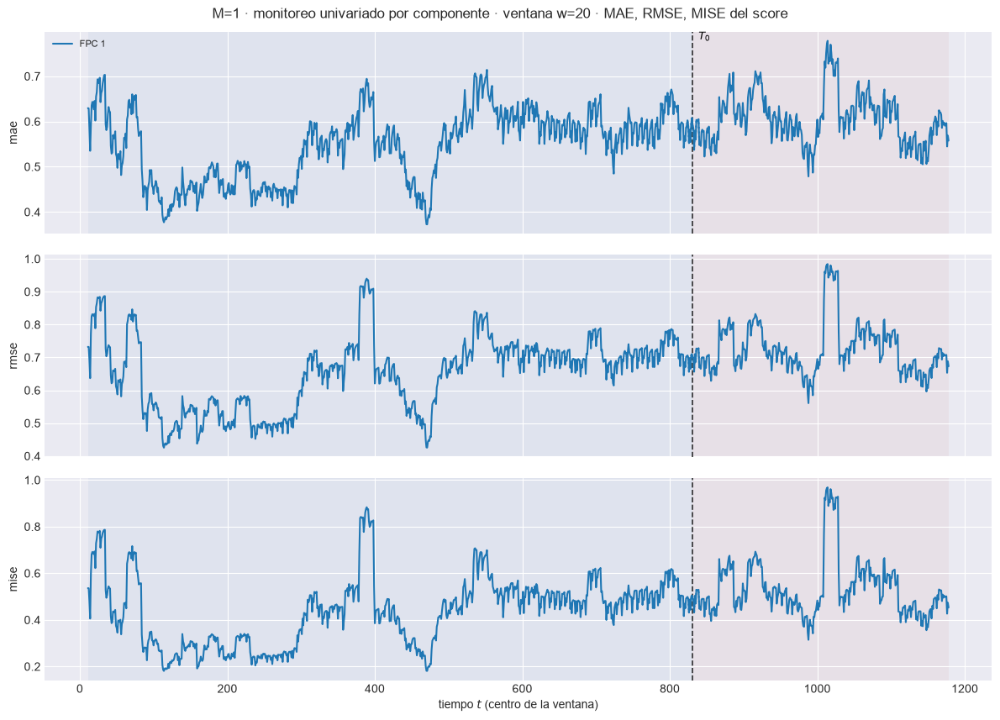

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.5639  w=30 test=0.6057


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.6801  w=30 test=0.7278


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.4626  w=30 test=0.5298


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m01\91_ventana_univariado_w30.png


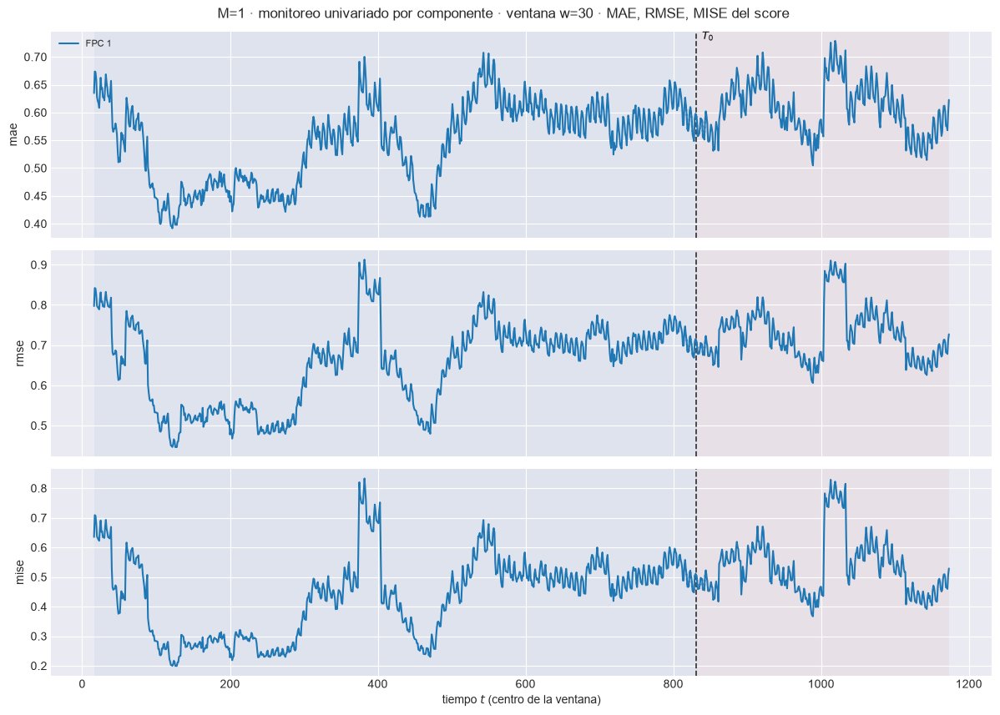

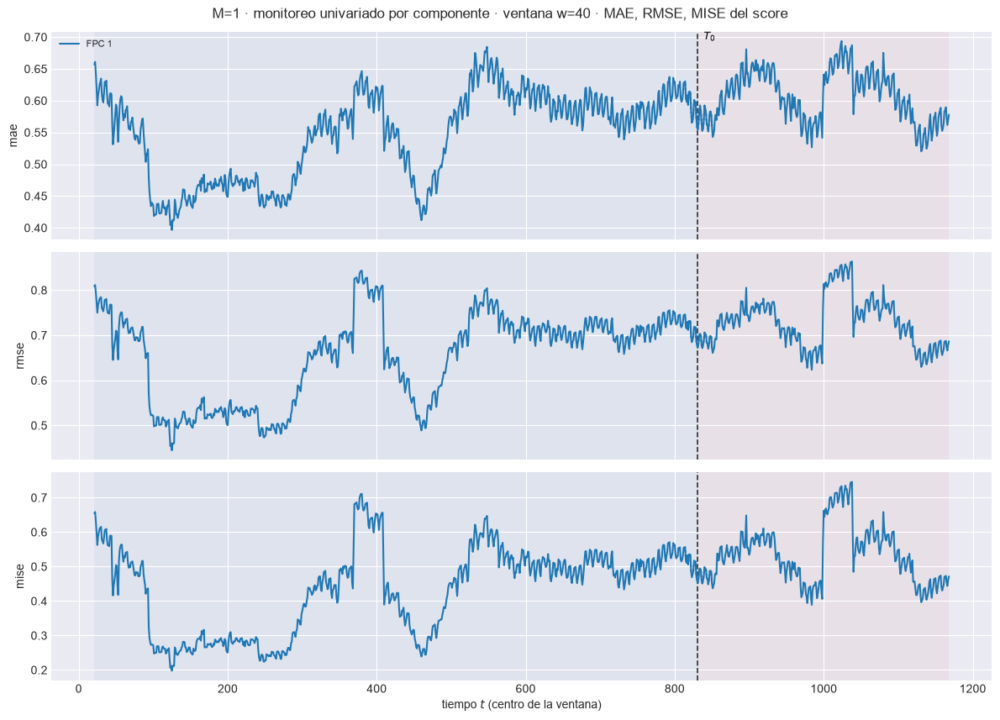

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=0.9s  t=16 [train] rmse=0.7567


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.6992


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.4169


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5719


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.4384


... (38 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.1565

  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.1721


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.1671


[ventana_movil_scores[FPC 2, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0

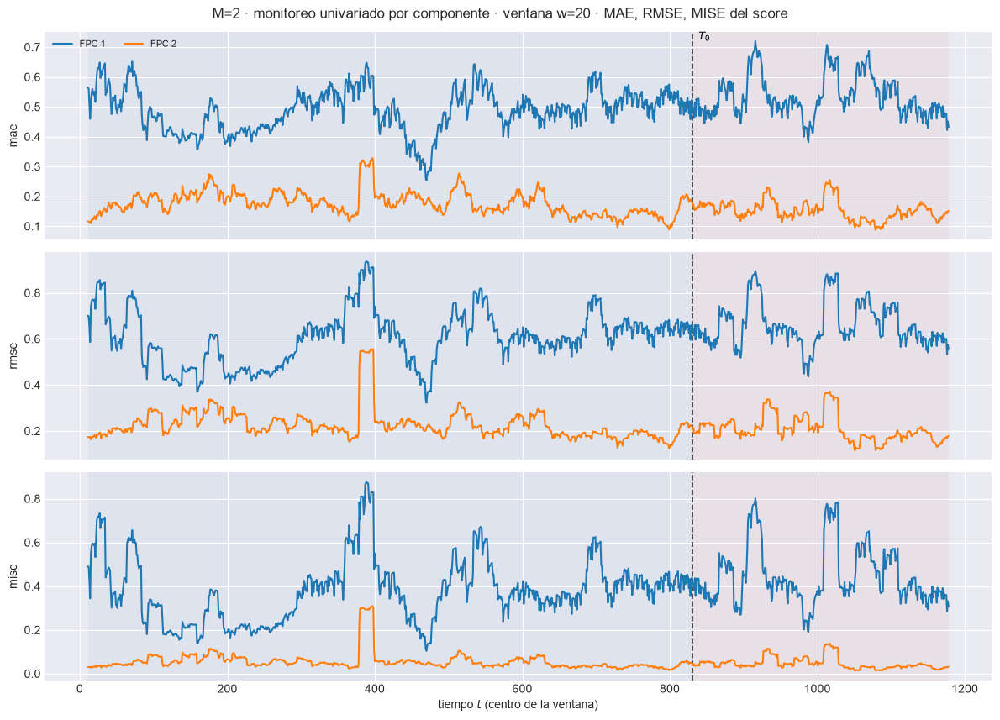

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2949  w=30 test=0.3181


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.4336  w=30 test=0.4088


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.188  w=30 test=0.1741


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m02\91_ventana_univariado_w30.png


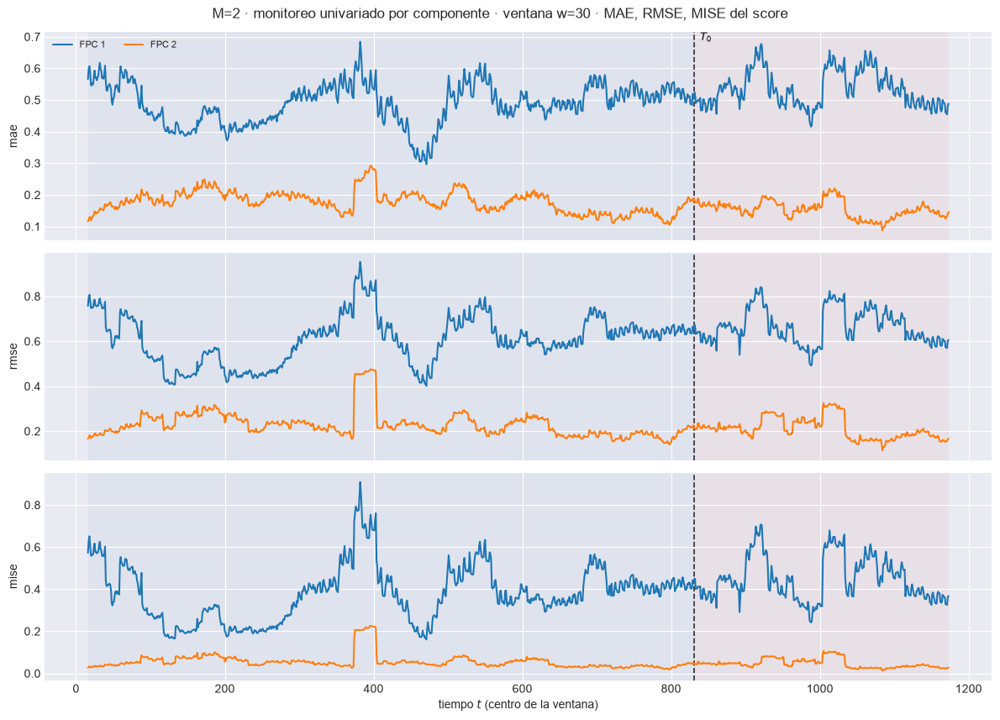

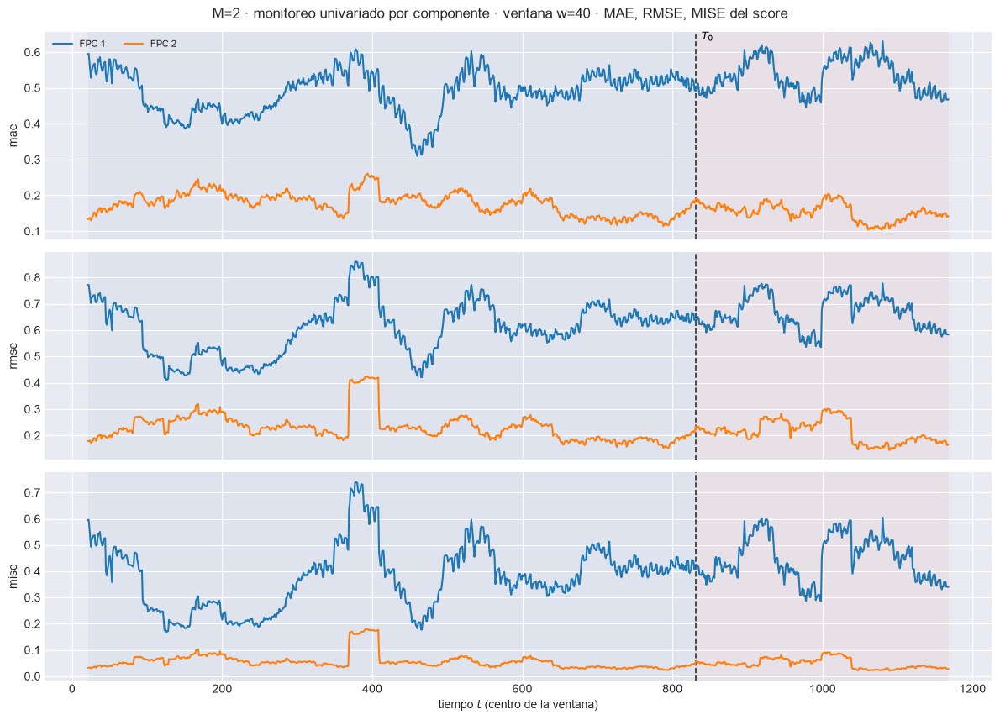

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=1.1s  t=16 [train] rmse=0.7815


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.6995


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.3936


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5131


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.3499


... (62 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.09078


  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.08487


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.1011


[ventana_movil_scores[FPC 3, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


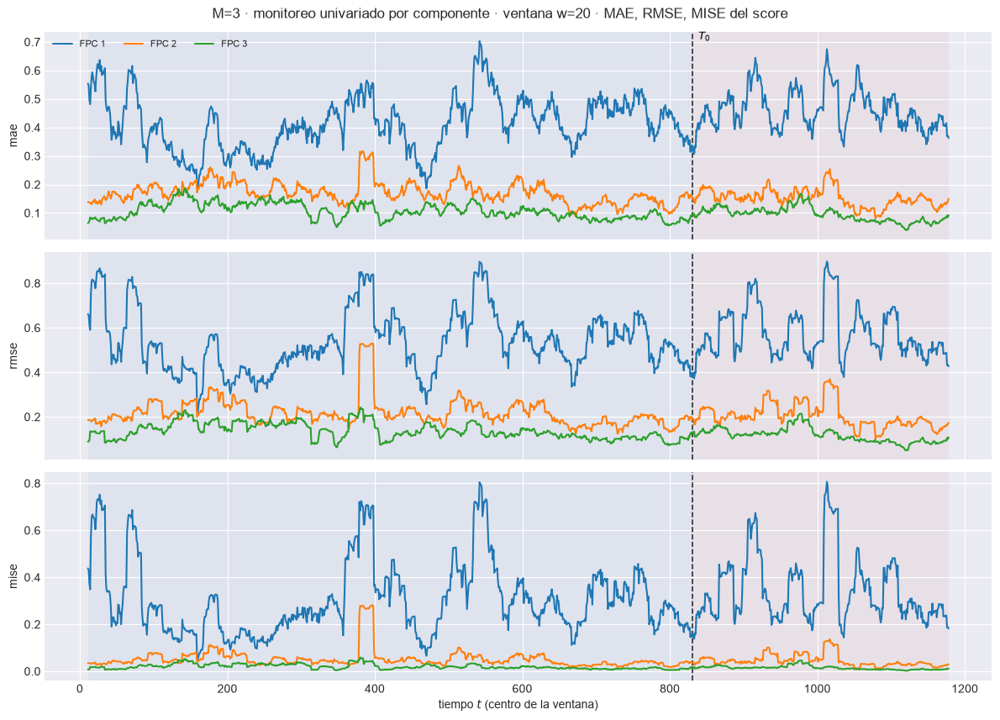

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.171  w=30 test=0.1536


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.213  w=30 test=0.198


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.04538  w=30 test=0.03919


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m03\91_ventana_univariado_w30.png


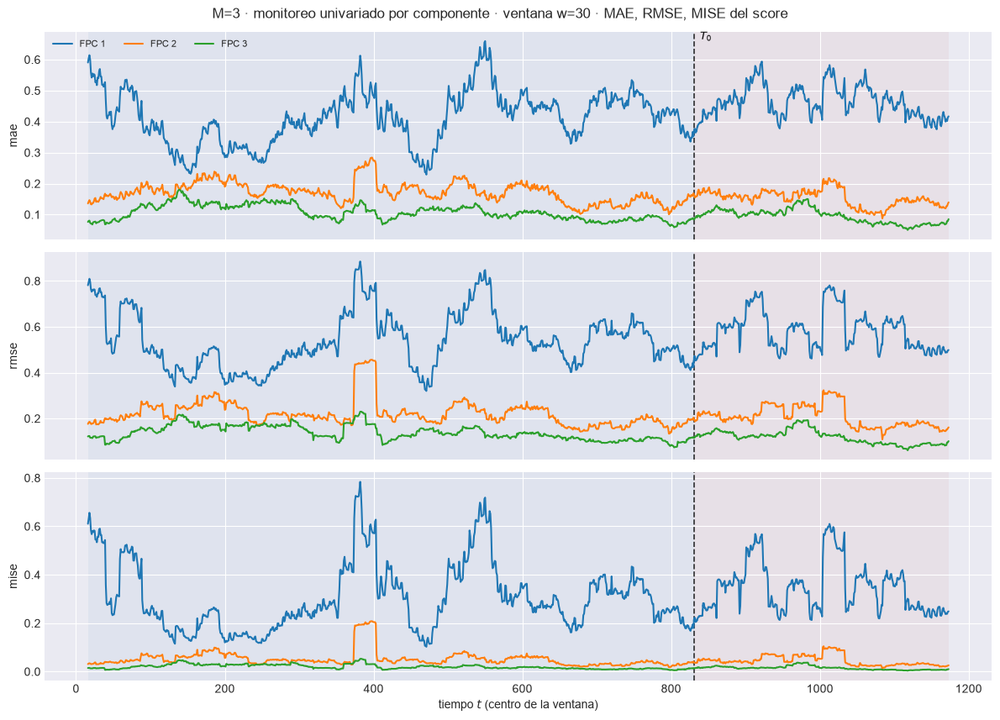

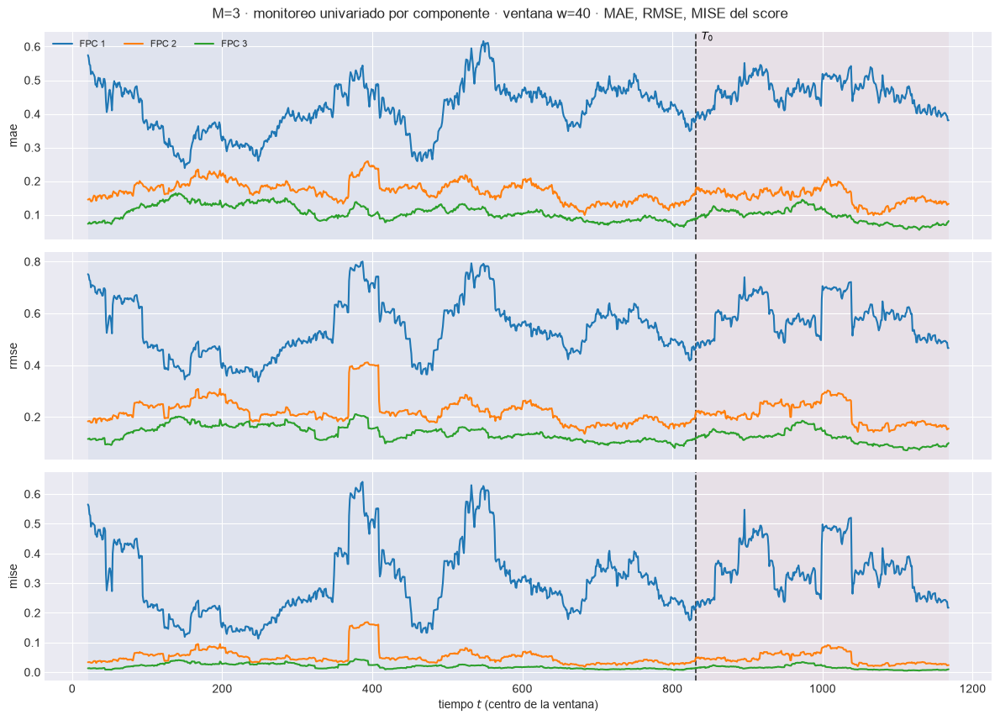

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=0.9s  t=16 [train] rmse=0.6725


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.5949


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.3734


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5276


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.3134


... (86 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.08694


  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.06401


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.06465


[ventana_movil_scores[FPC 4, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


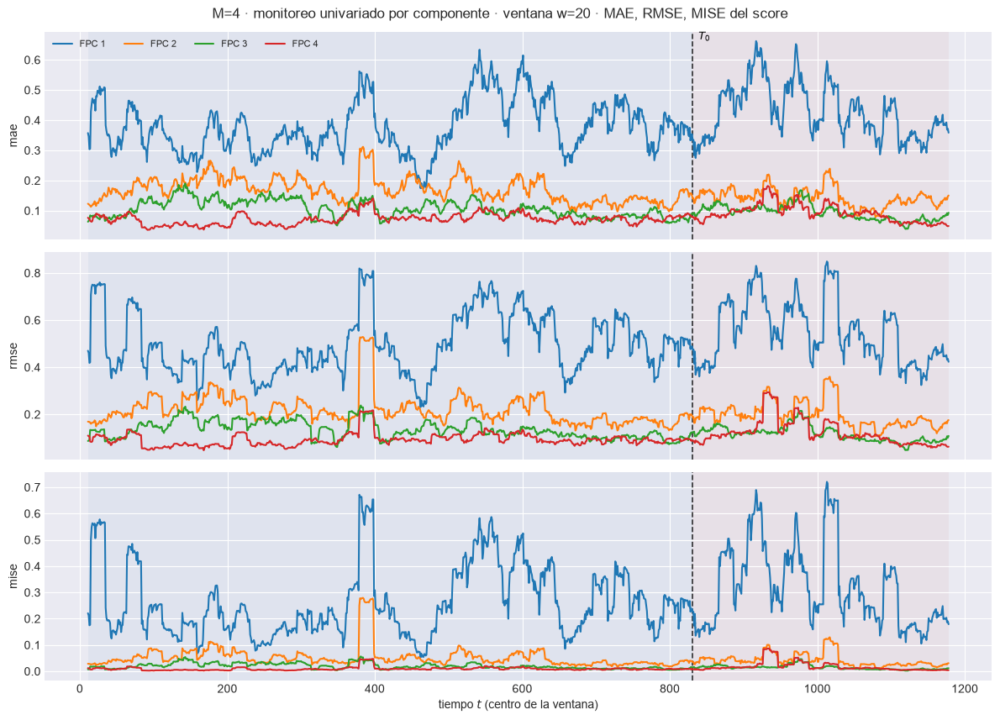

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1348  w=30 test=0.1243


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1745  w=30 test=0.1596


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.03047  w=30 test=0.02546


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m04\91_ventana_univariado_w30.png


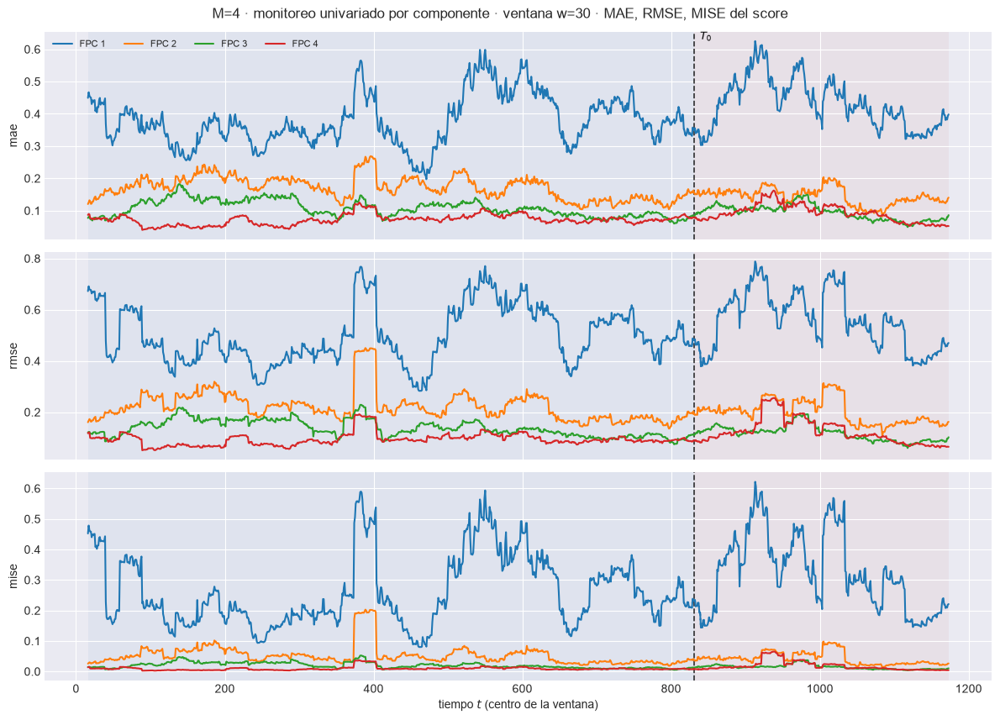

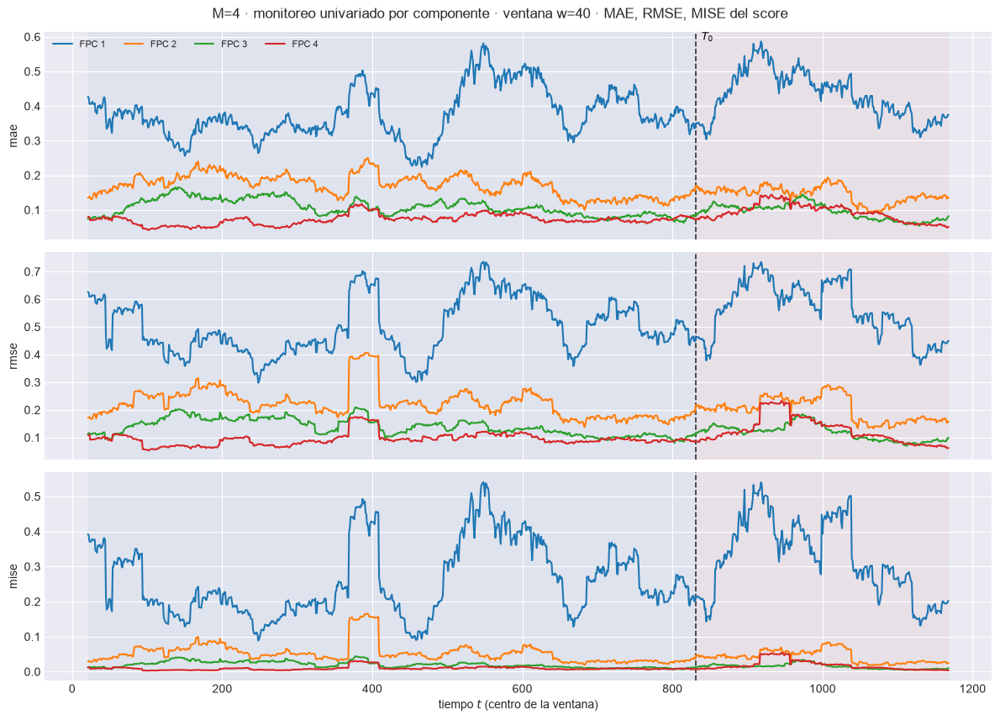

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=0.9s  t=16 [train] rmse=0.665


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.6056


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.3921


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5207


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.2943


... (110 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.05698


  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.05611


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.05566


[ventana_movil_scores[FPC 5, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


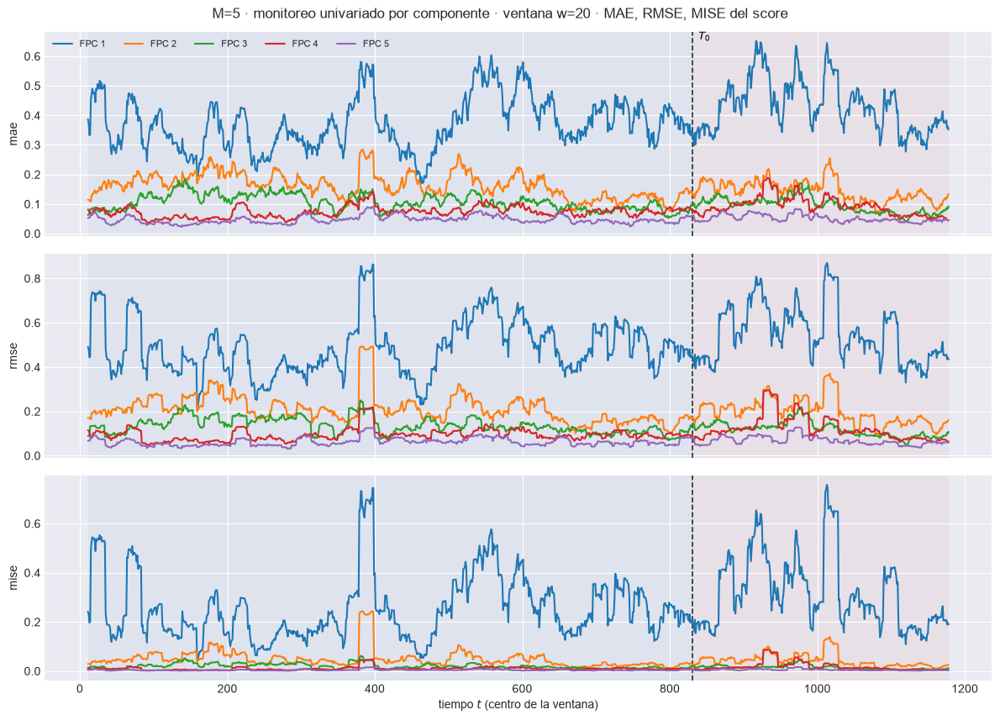

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.1042  w=30 test=0.107


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1332  w=30 test=0.1377


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.01773  w=30 test=0.01895


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m05\91_ventana_univariado_w30.png


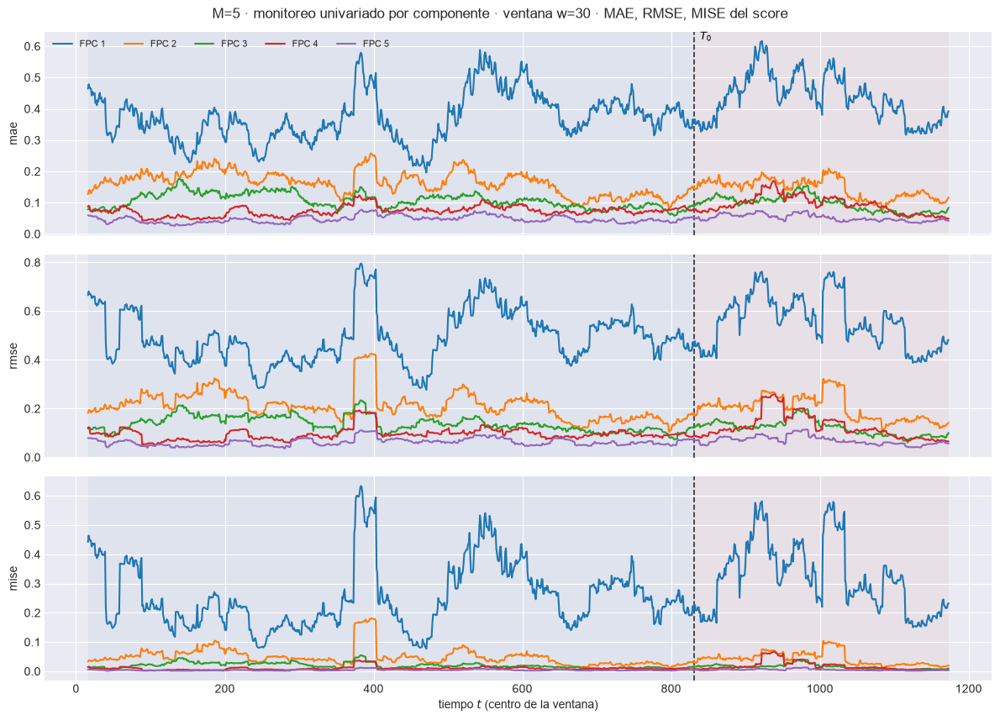

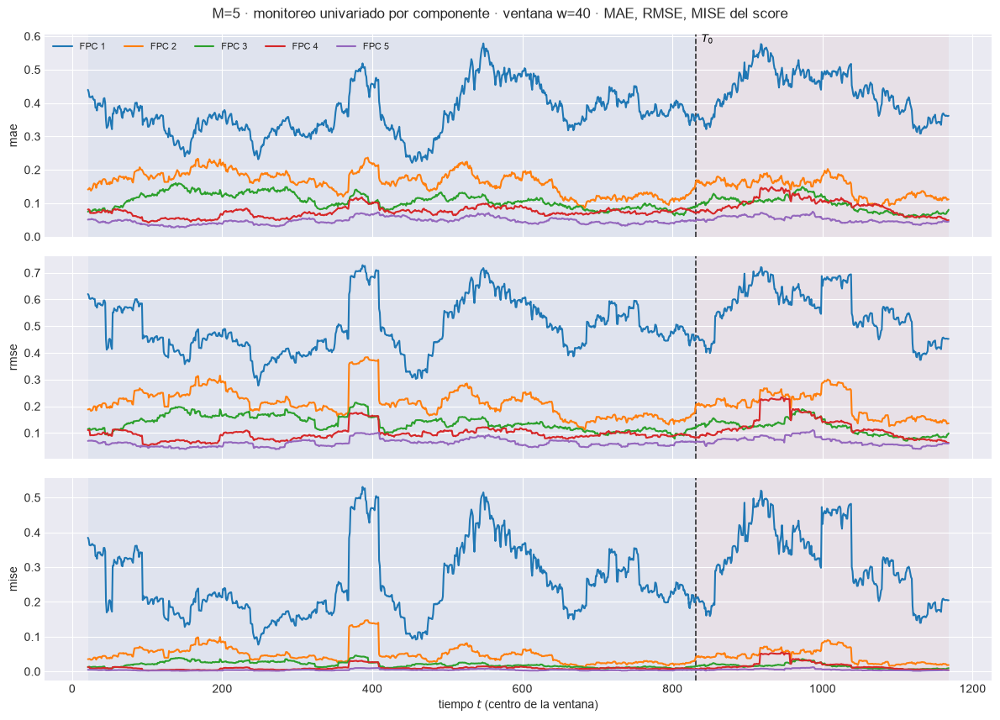

[ventana_movil_scores[FPC 1, w=30]] inicio (1158 pasos)


  1/1158 ( 0.1%) t=0.0s eta=0.9s  t=16 [train] rmse=0.6808


  57/1158 ( 4.9%) t=0.0s eta=0.1s  t=72 [train] rmse=0.5699


  114/1158 ( 9.8%) t=0.0s eta=0.1s  t=129 [train] rmse=0.3894


  171/1158 (14.8%) t=0.0s eta=0.1s  t=186 [train] rmse=0.5377


  228/1158 (19.7%) t=0.0s eta=0.1s  t=243 [train] rmse=0.3299


... (134 outputs left out)

  1083/1158 (93.5%) t=0.1s eta=0.0s  t=1098 [test] rmse=0.05406


  1140/1158 (98.4%) t=0.1s eta=0.0s  t=1155 [test] rmse=0.06708


  1158/1158 (100.0%) t=0.1s eta=0.0s  t=1173 [test] rmse=0.08558


[ventana_movil_scores[FPC 6, w=30]] listo: 1158 pasos en 0.1s  29 ventanas cruzan T0


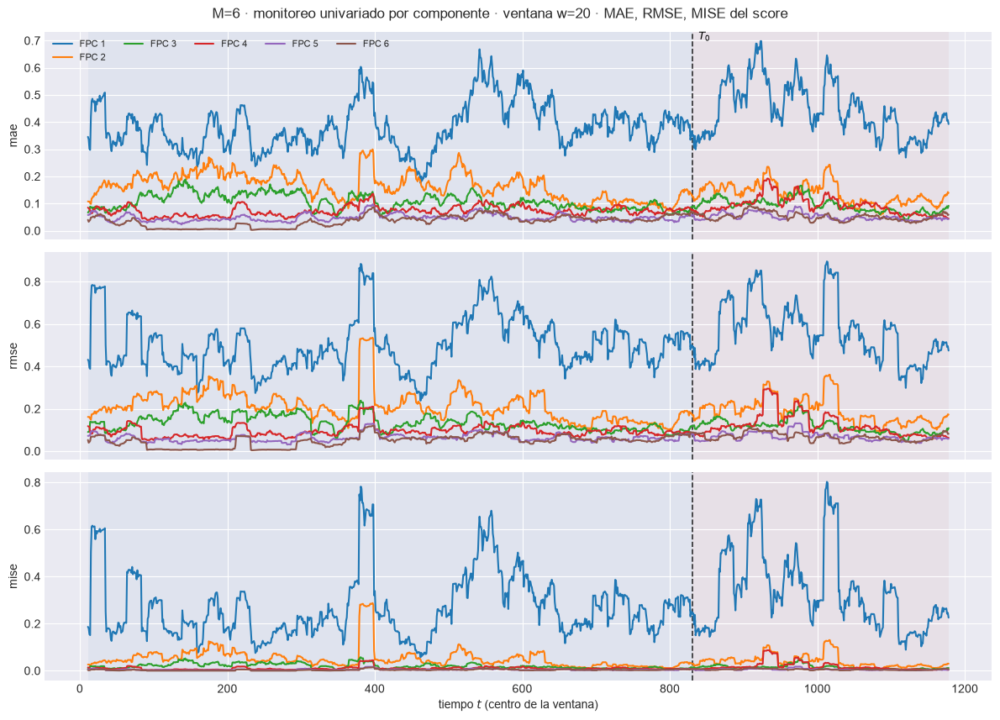

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.08414  w=30 test=0.0923


  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.1089  w=30 test=0.1153


  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.01186  w=30 test=0.01329


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m06\91_ventana_univariado_w30.png


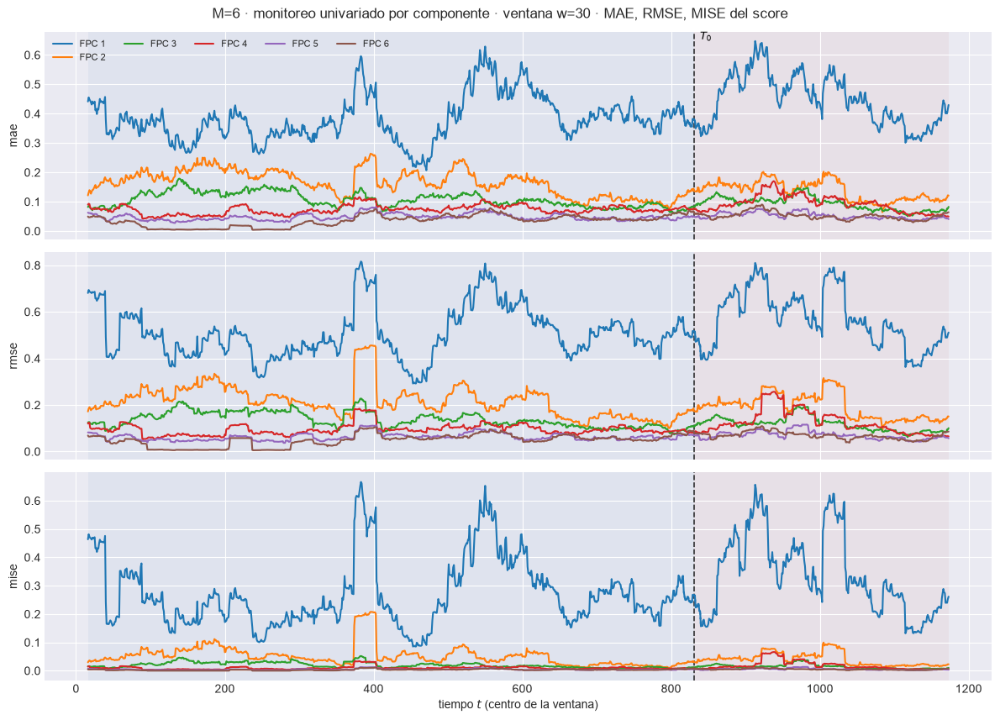

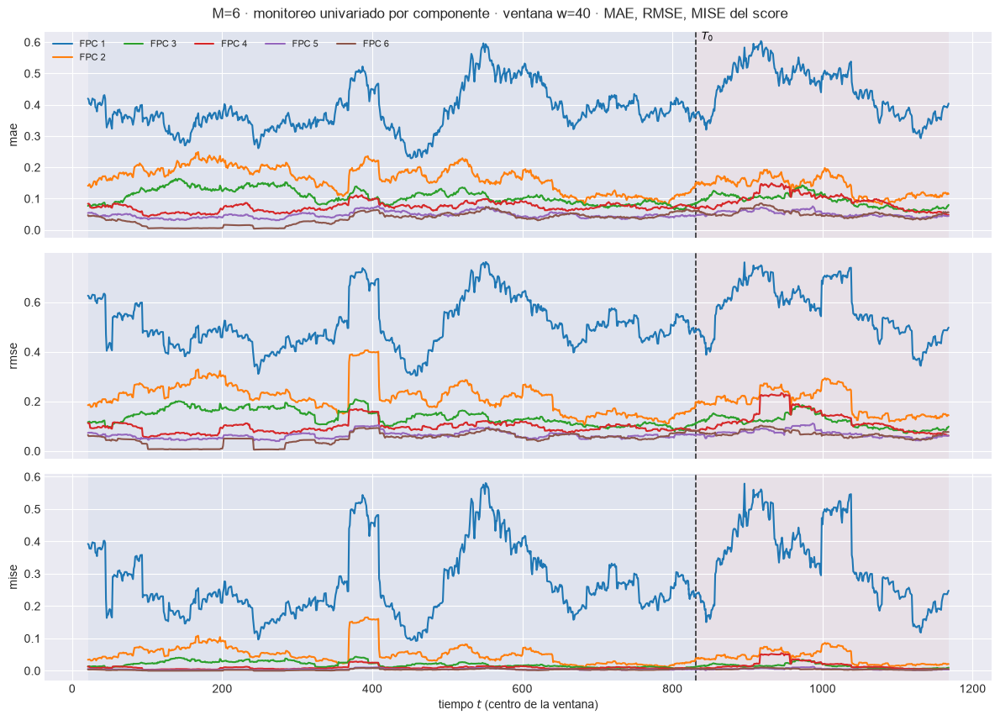

In [15]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

Las secciones anteriores miran la **curva**, que es el producto final. Ésta
mira el objeto que el muestreador predice de verdad: el score $\xi_{t,k}$ de
cada componente. La curva sale de propagarlos, así que un problema de
calibración que aquí se vea localizado en una componente queda, allá,
promediado con las demás y es mucho más difícil de atribuir.

| | qué muestra |
|---|---|
| **§10.1** | el intervalo de credibilidad de cada $\xi_k$ a lo largo del tiempo, con $\xi$ observado encima |
| **§10.2** | las métricas de ese intervalo: PICP, MPIW, Winkler, ACE — globales por bloque y sobre la ventana móvil, un panel por ancho |
| **§10.3** | dispersión $\hat\xi$ contra $\xi$ con la diagonal, componente a componente |

La banda es `li_s`/`ls_s`, los cuantiles muestrales de la predictiva por score
que §3 ya calculó: es **la misma** de la que sale la banda funcional, antes de
propagarla. No se vuelve a muestrear nada.


### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

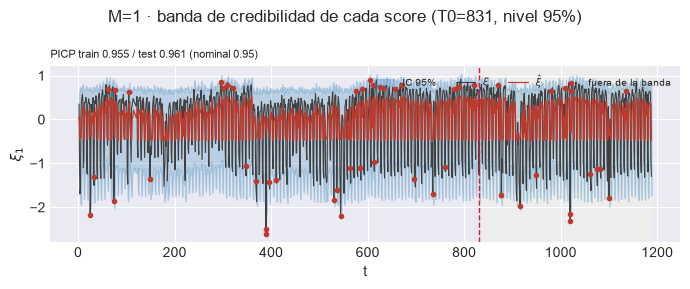

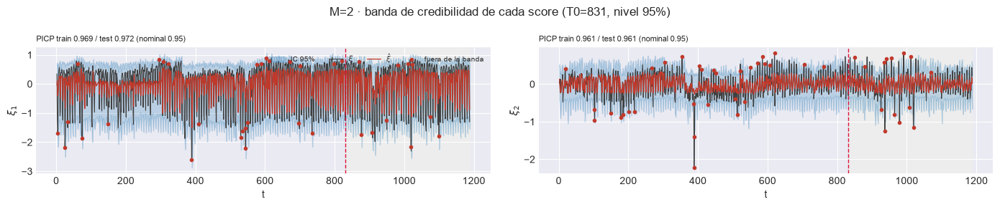

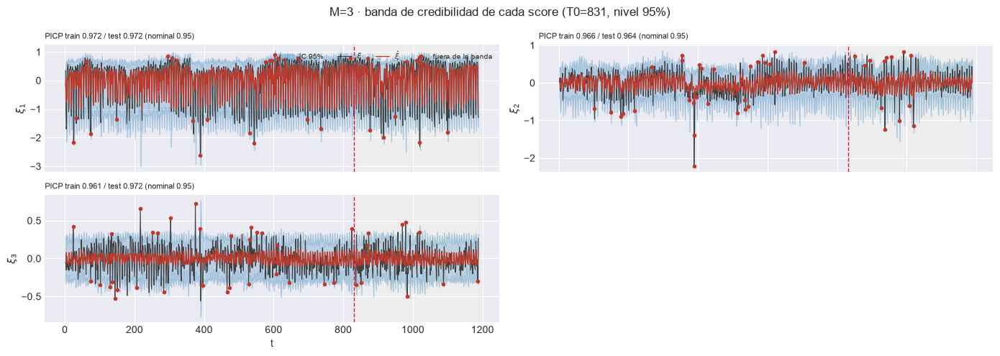

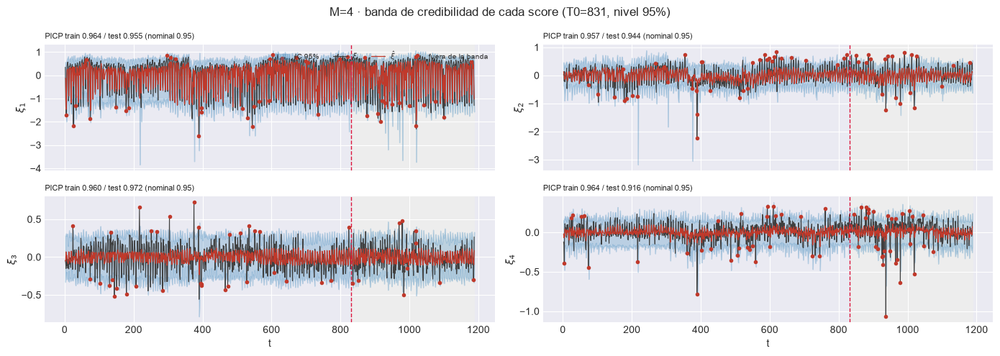

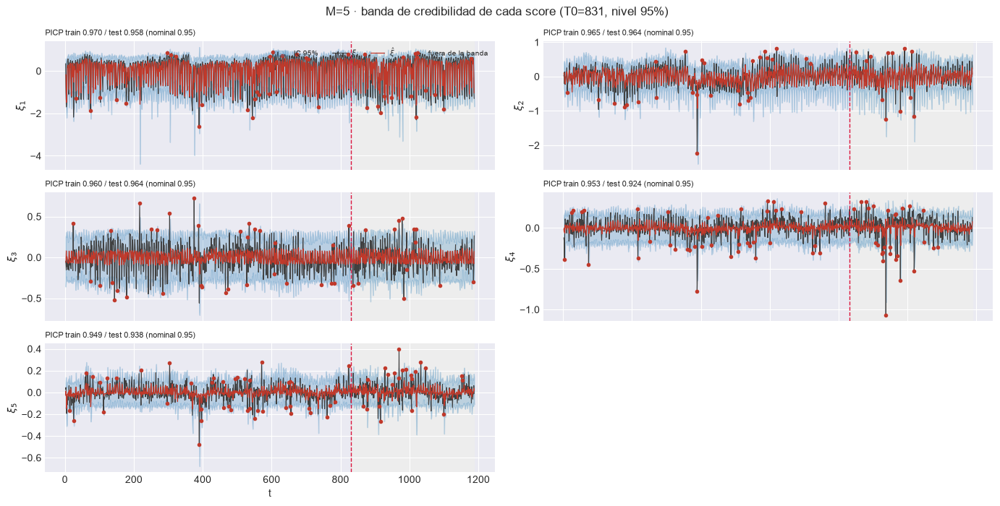

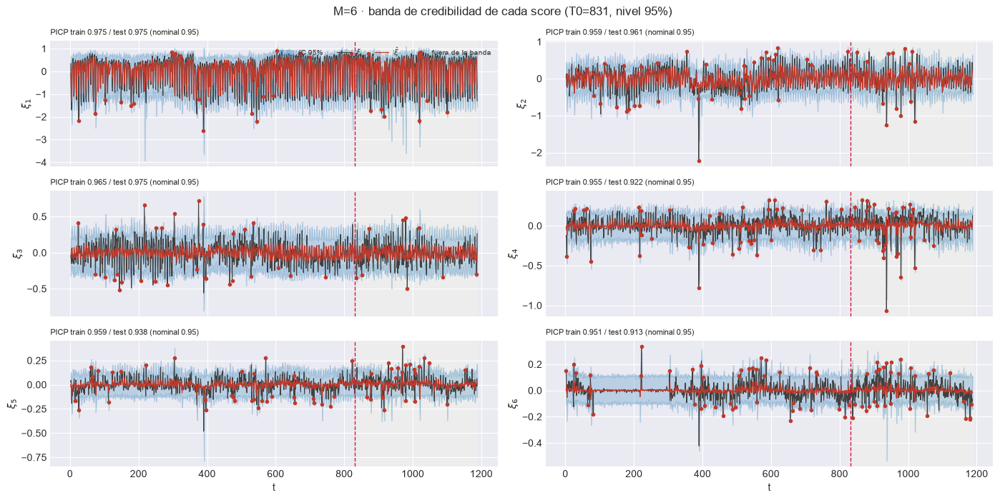

In [16]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

Las mismas cuatro cifras del Bloque B, pero por componente y en la escala del
score: **PICP** (fracción de orígenes cubiertos), **MPIW** (ancho medio),
**Winkler** (regla de puntuación que penaliza ancho y fallo a la vez) y
**ACE** = PICP − nominal, que es el signo de la miscalibración: negativo es
subcobertura.

Primero la lectura global por bloque; después la evolución sobre la ventana
móvil, **un panel por ancho**, con el mismo criterio de §4 y §5.


OK ninguna componente se aleja mas de 0.1 del nominal en test.


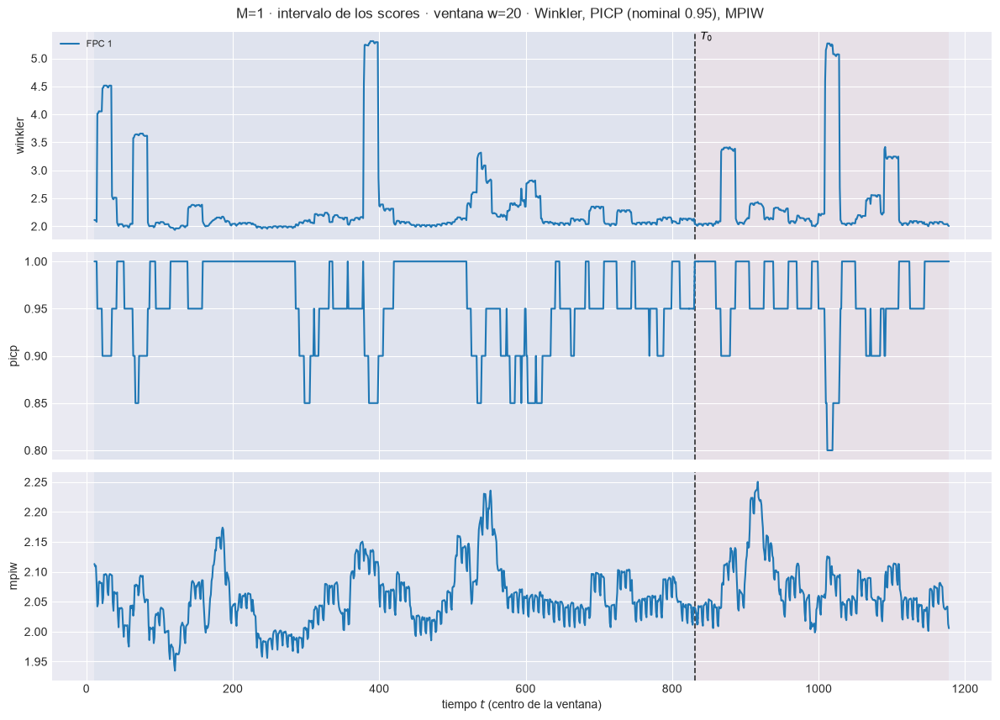

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=2.116  w=30 test=2.232


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=2.054  w=30 test=2.07


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m01\93_ventana_scores_intervalo_w30.png


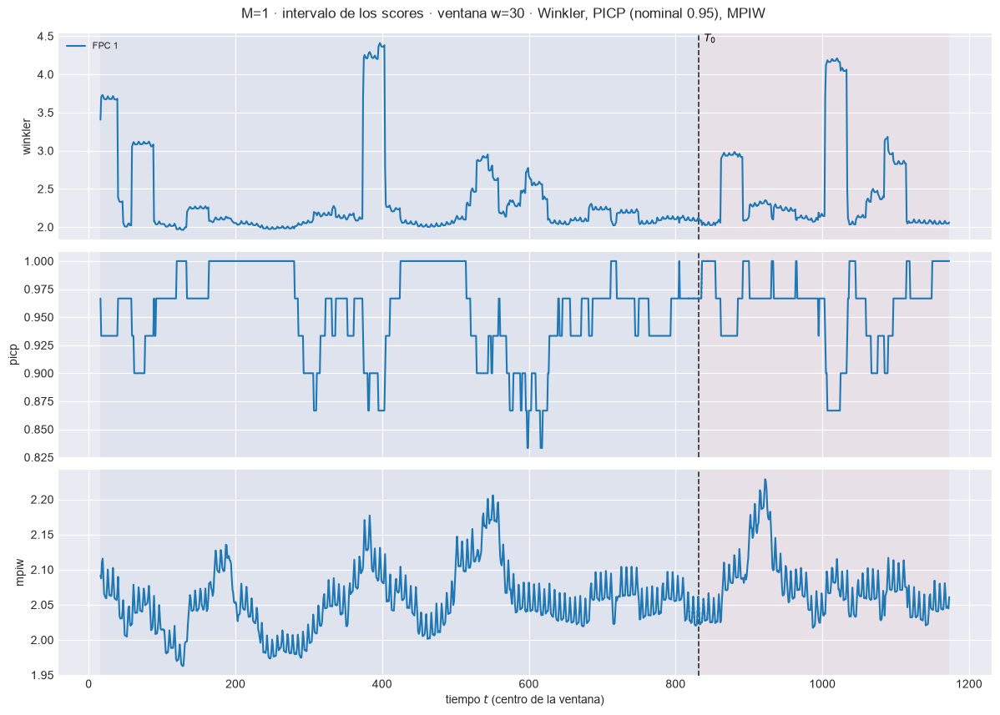

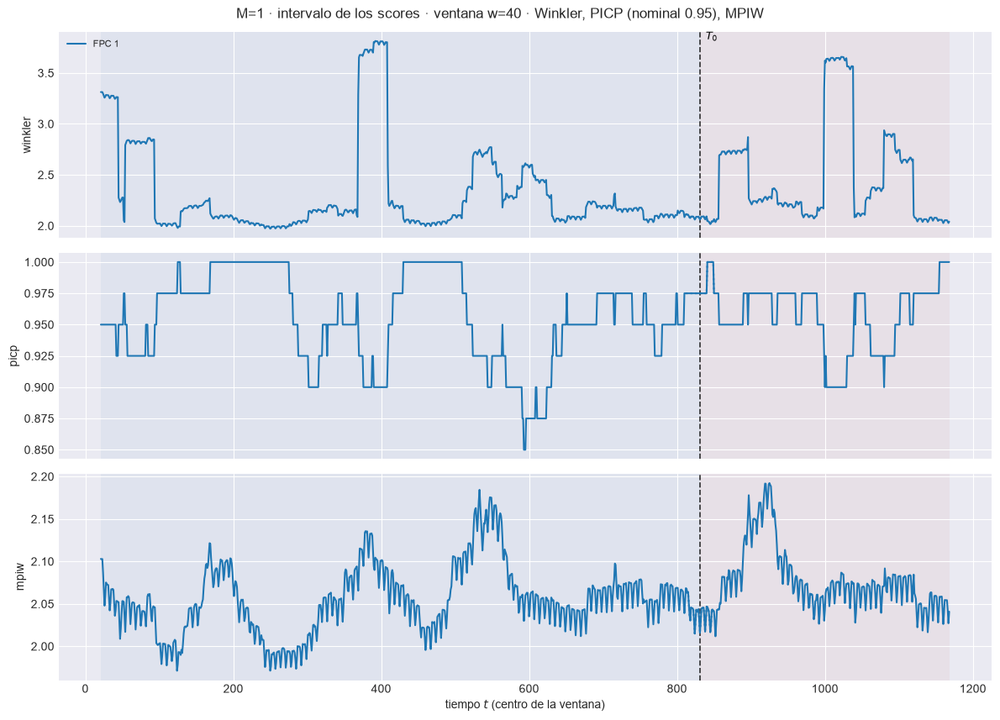

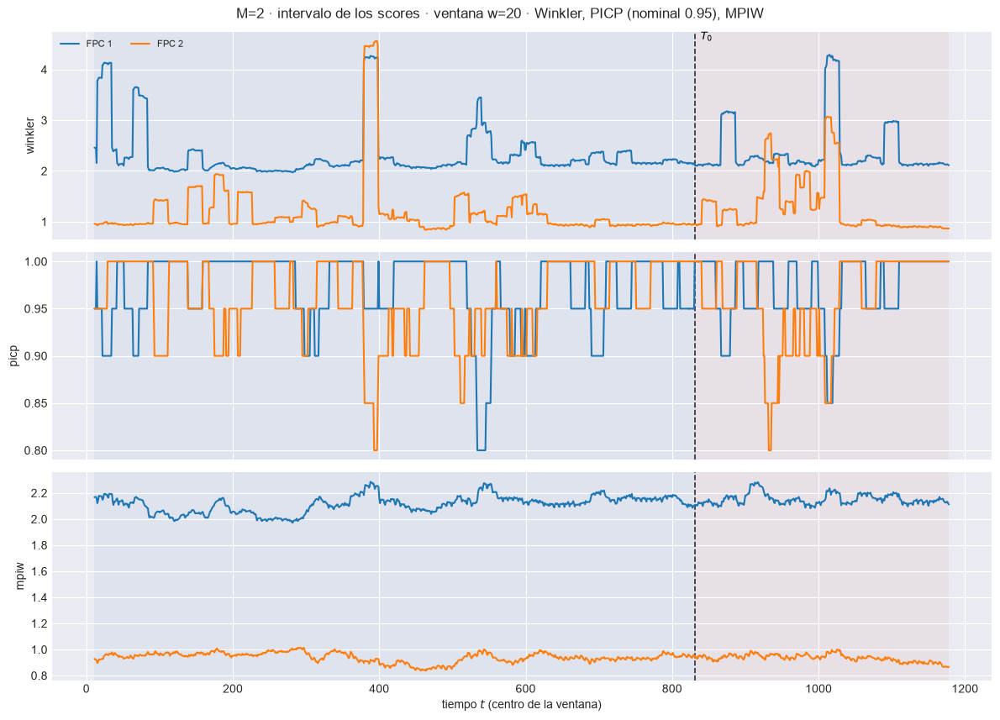

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.999  w=30 test=2.127


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.496  w=30 test=1.543


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m02\93_ventana_scores_intervalo_w30.png


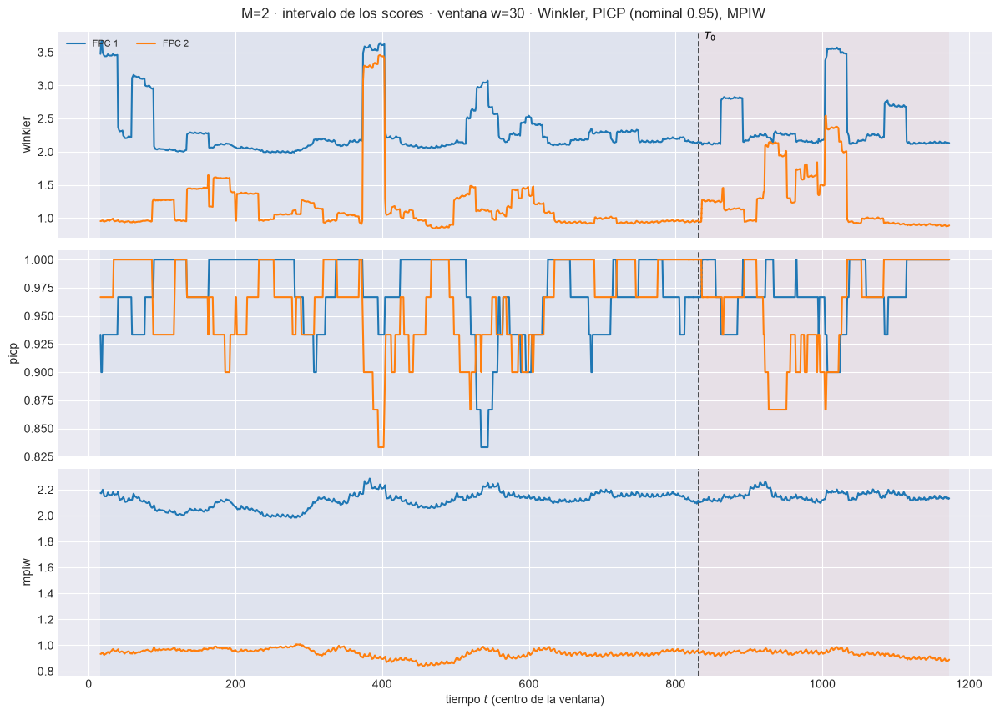

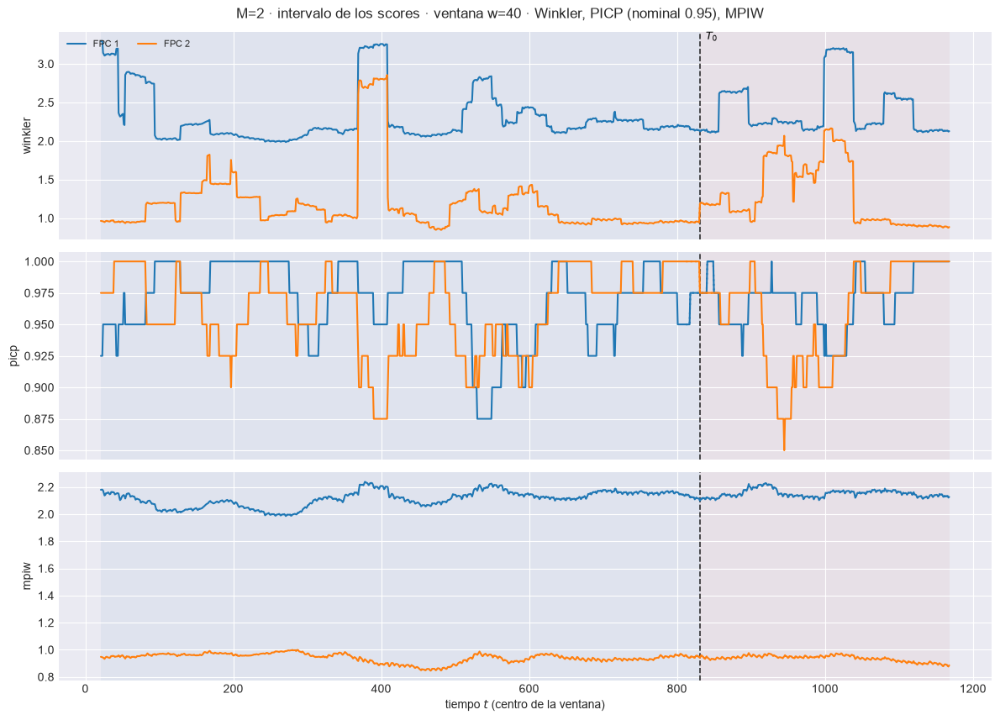

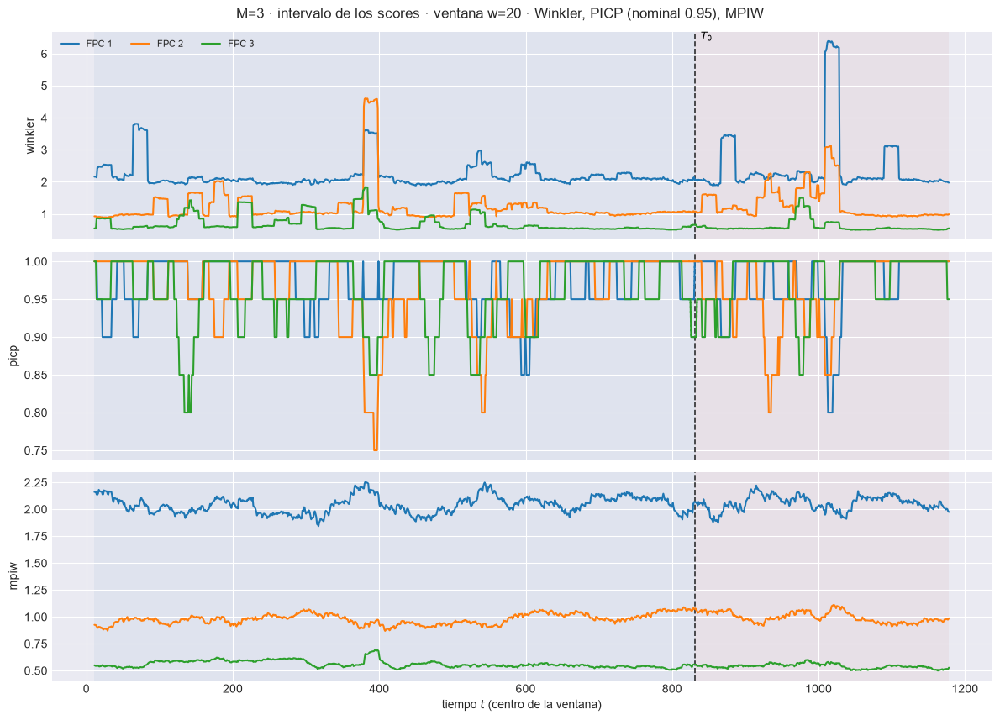

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.103  w=30 test=1.178


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.9765  w=30 test=0.9851


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m03\93_ventana_scores_intervalo_w30.png


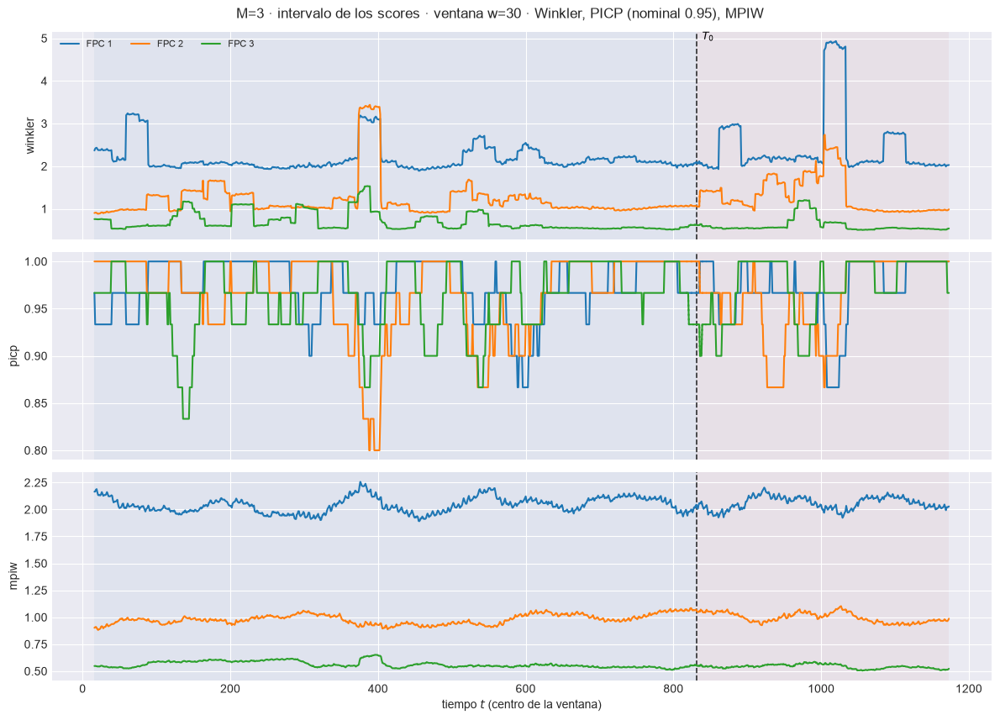

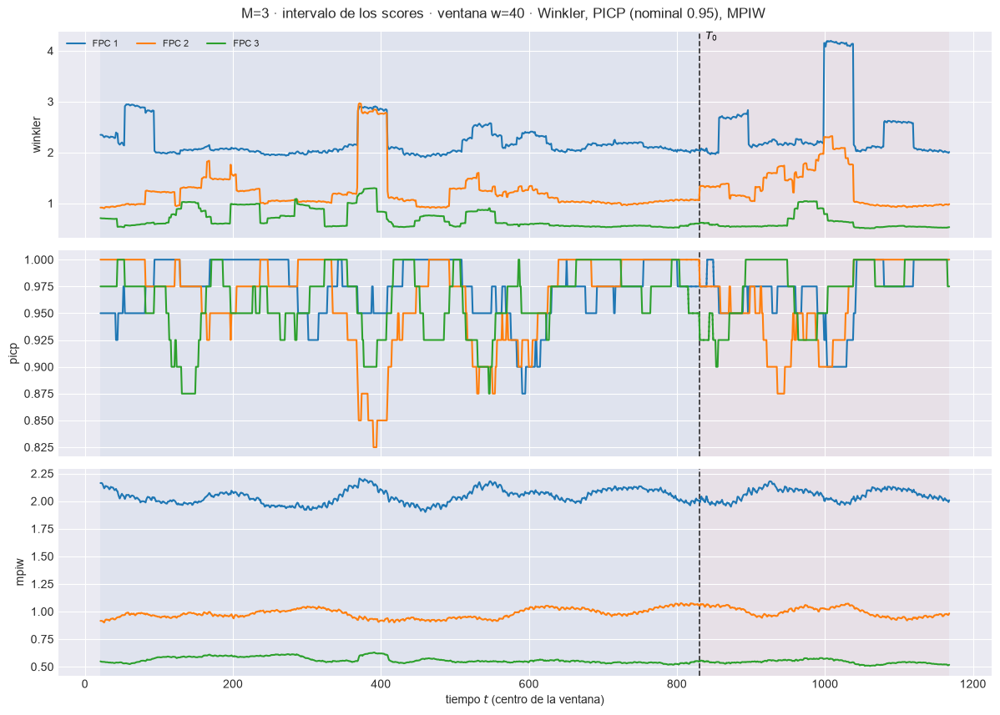

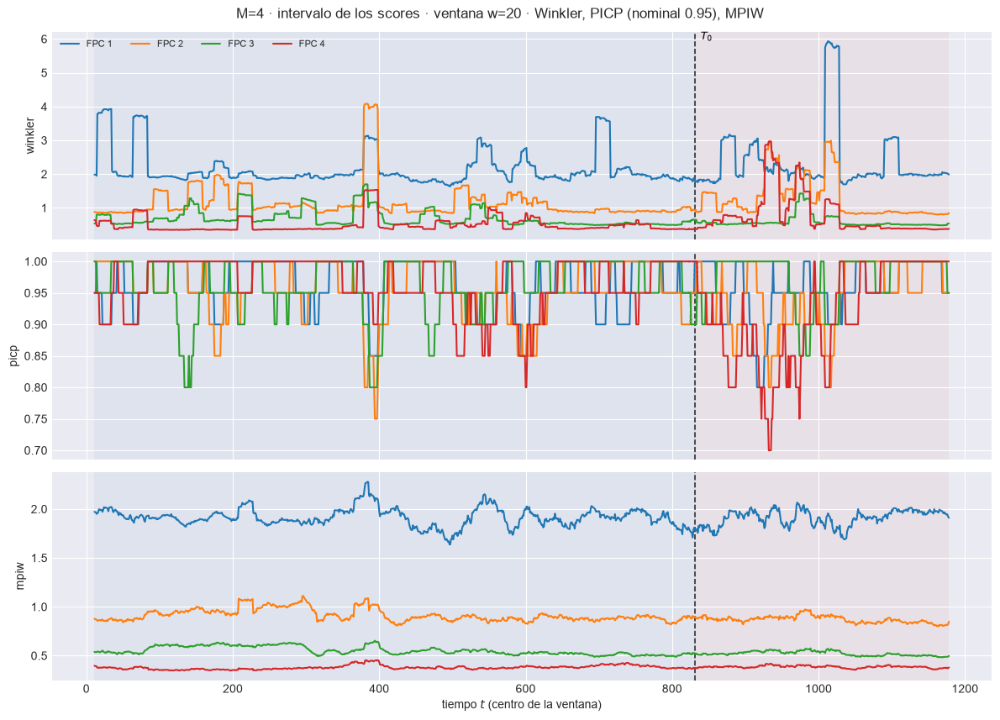

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.9007  w=30 test=0.8754


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.7285  w=30 test=0.6848


[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m04\93_ventana_scores_intervalo_w30.png


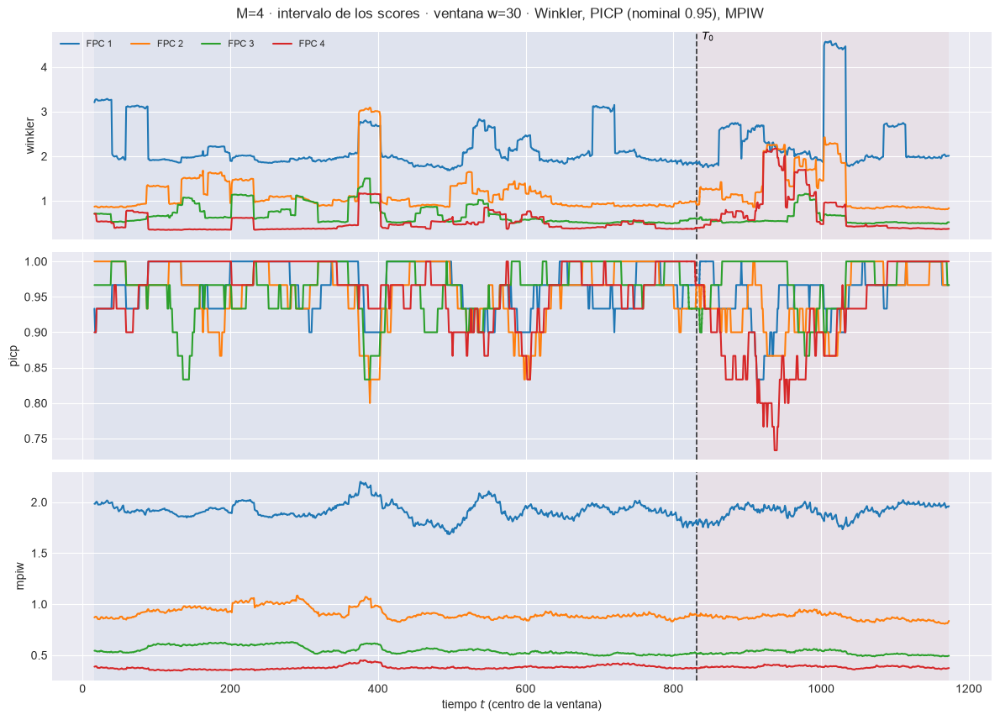

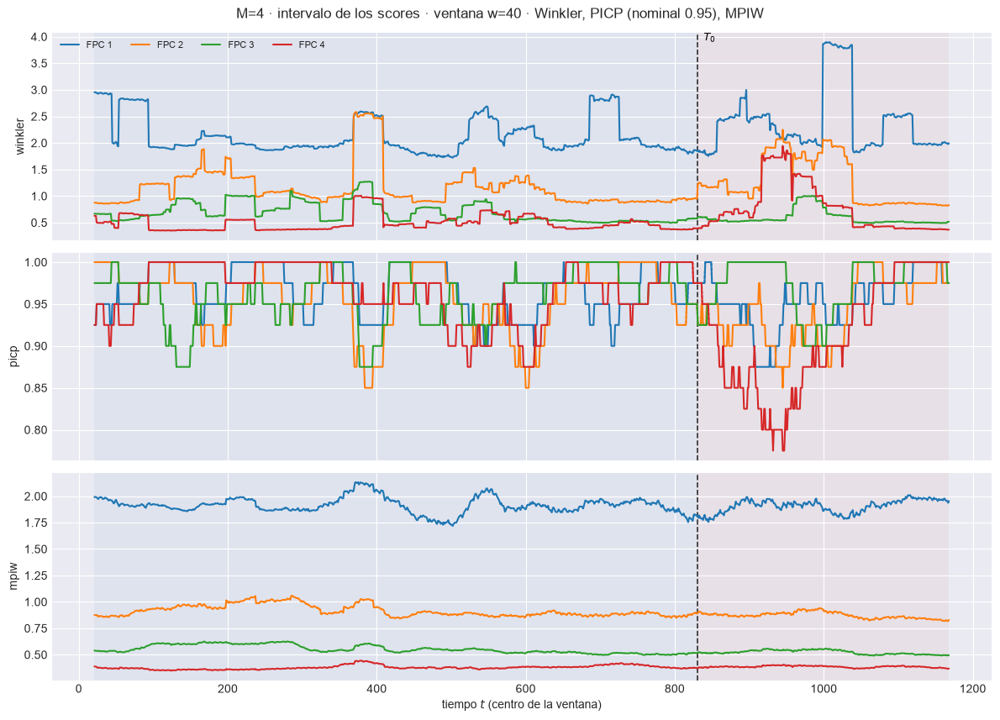

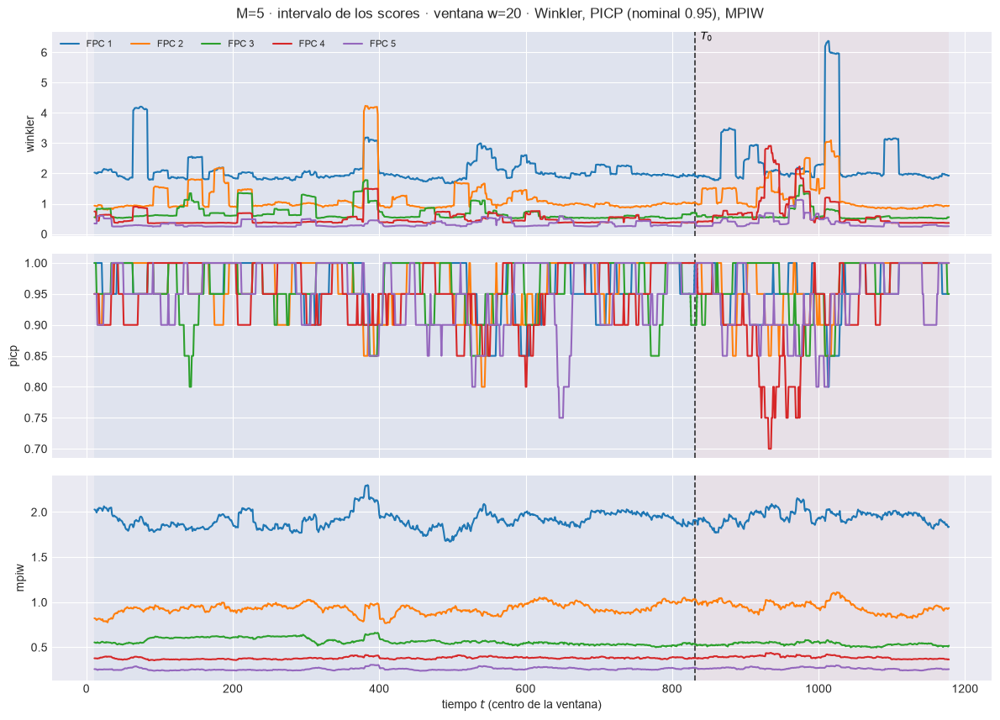

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.6651  w=30 test=0.8039


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.5588  w=30 test=0.5366


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m05\93_ventana_scores_intervalo_w30.png


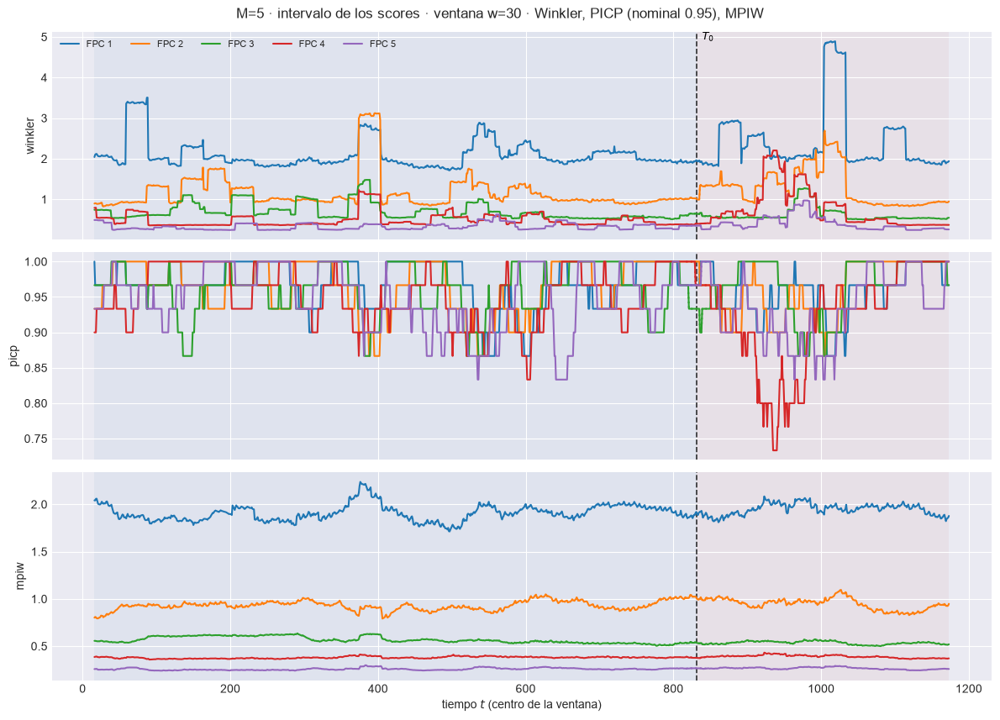

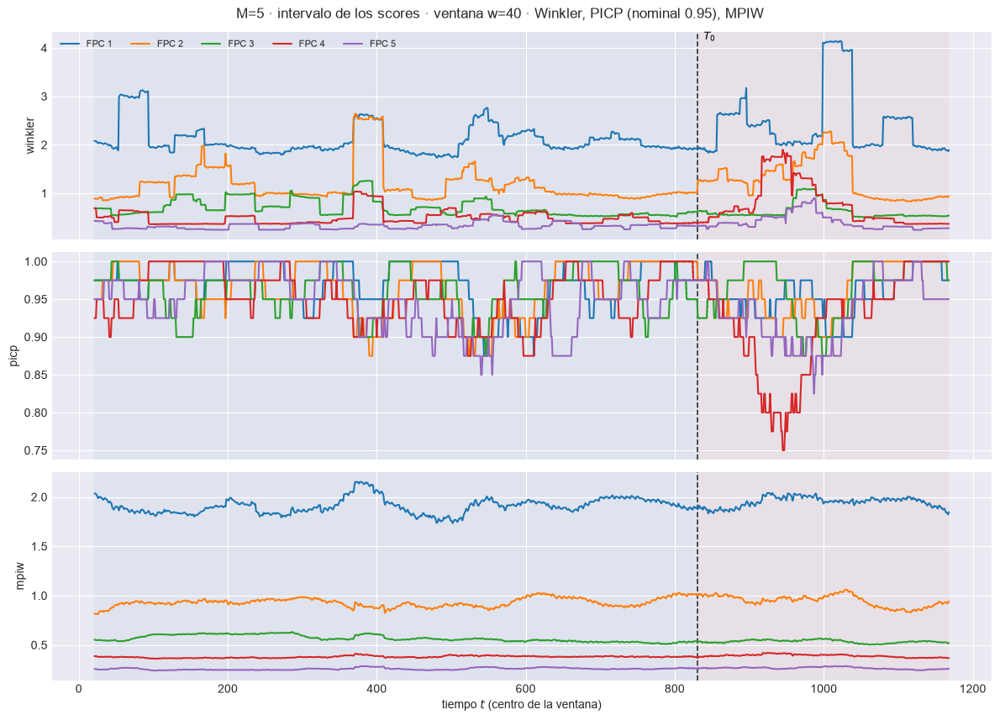

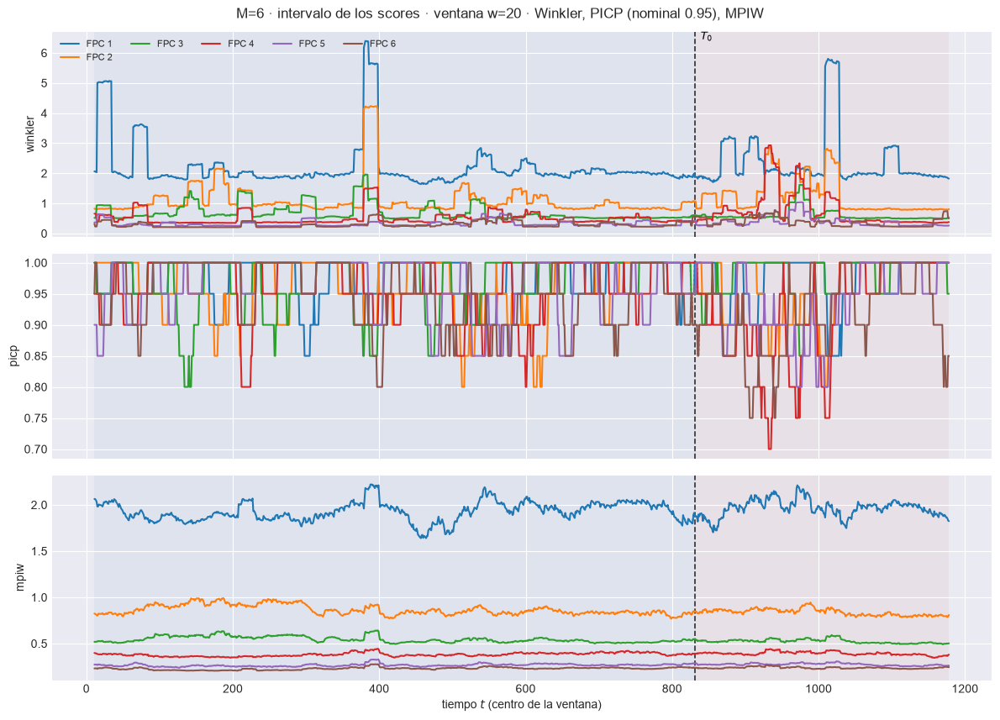

[plot_ventana_movil] inicio (3 pasos)


  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=0.5344  w=30 test=0.5773


  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667


  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=0.4683  w=30 test=0.4625


[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\reales\real_trafico_mi_v01_m06\93_ventana_scores_intervalo_w30.png


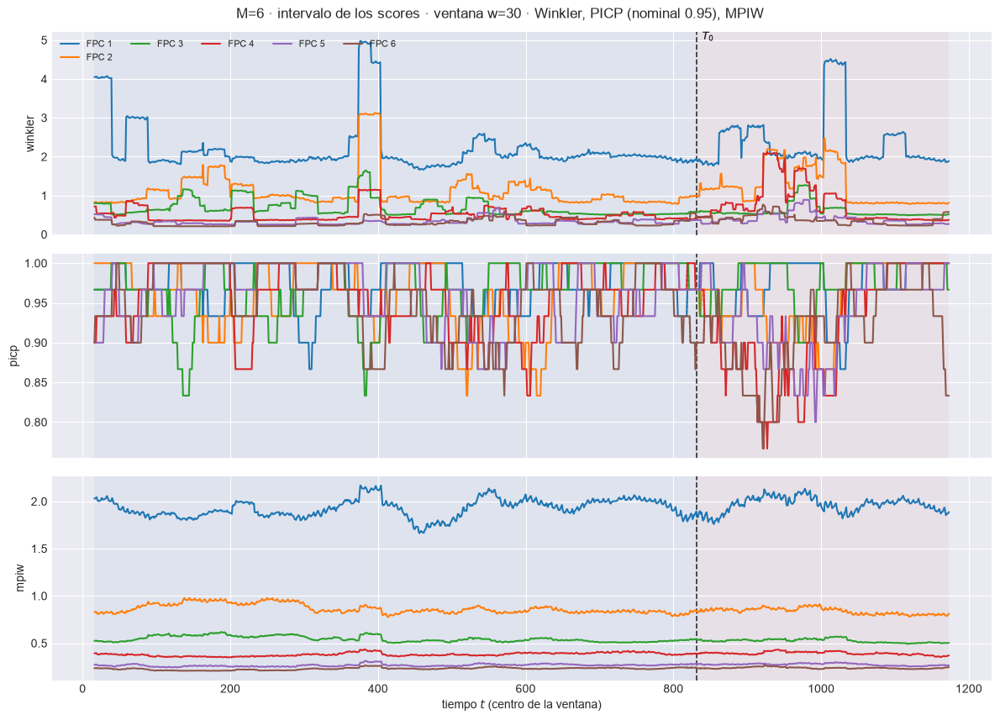

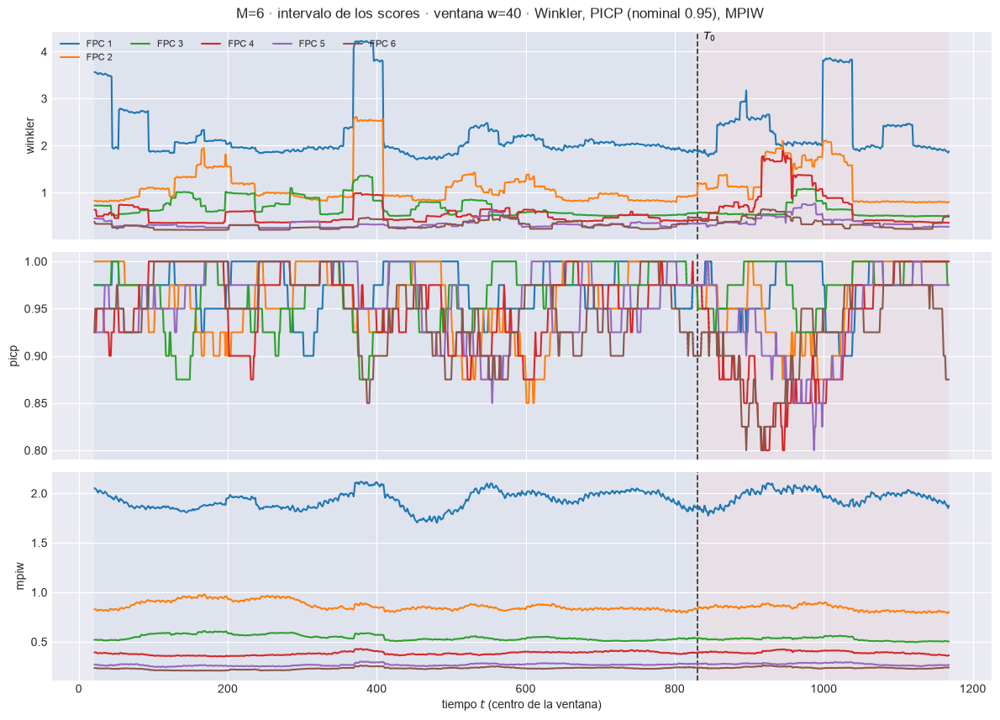

In [17]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente, con la diagonal $y=x$. Tres cosas se leen de golpe:

- **la nube pegada a la diagonal** es predicción; la nube **horizontal**
  —$\hat\xi$ casi constante mientras $\xi$ varía— es el modelo prediciendo la
  media incondicional, que es lo que pasa cuando la componente no tiene
  dinámica que capturar;
- **la pendiente** de la recta ajustada: menor que 1 es encogimiento hacia la
  media, que es el comportamiento esperado de un predictor bayesiano y no un
  defecto;
- **las barras** son el intervalo de credibilidad de una submuestra, de modo
  que se ve si los puntos que se salen de la diagonal están cubiertos.

Los puntos de train y de test van con marcador distinto: si la nube de test se
descuelga de la diagonal mientras la de train no, es deriva del bloque de
prueba y no error de ajuste.


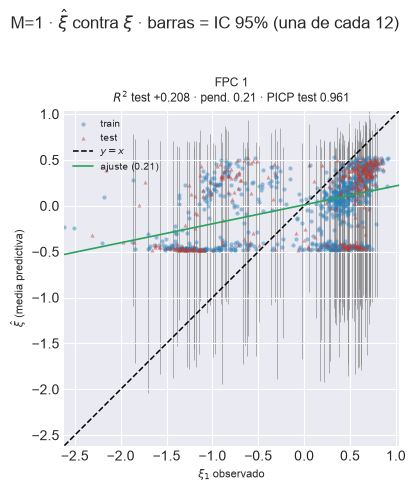

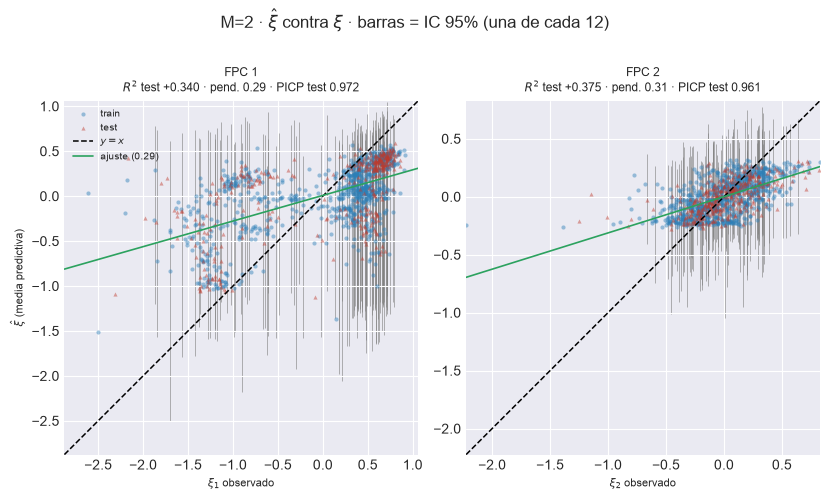

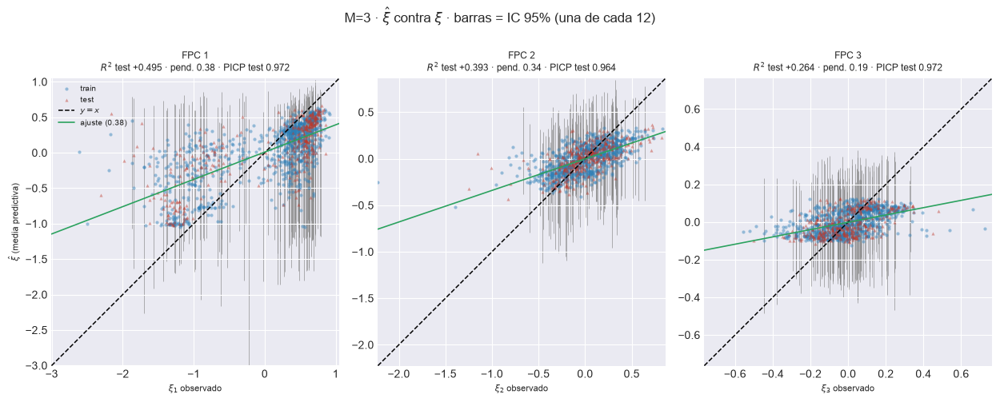

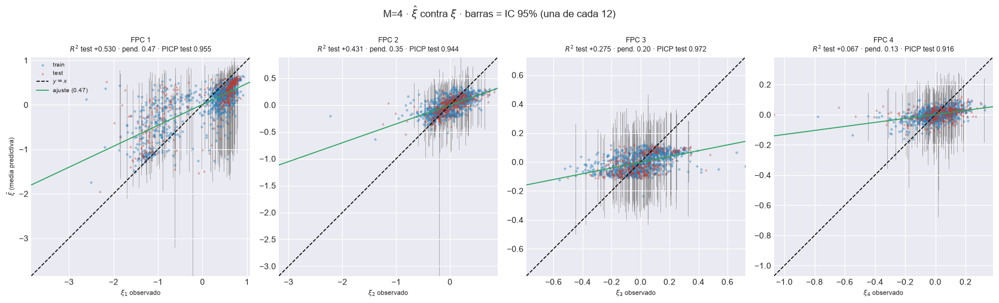

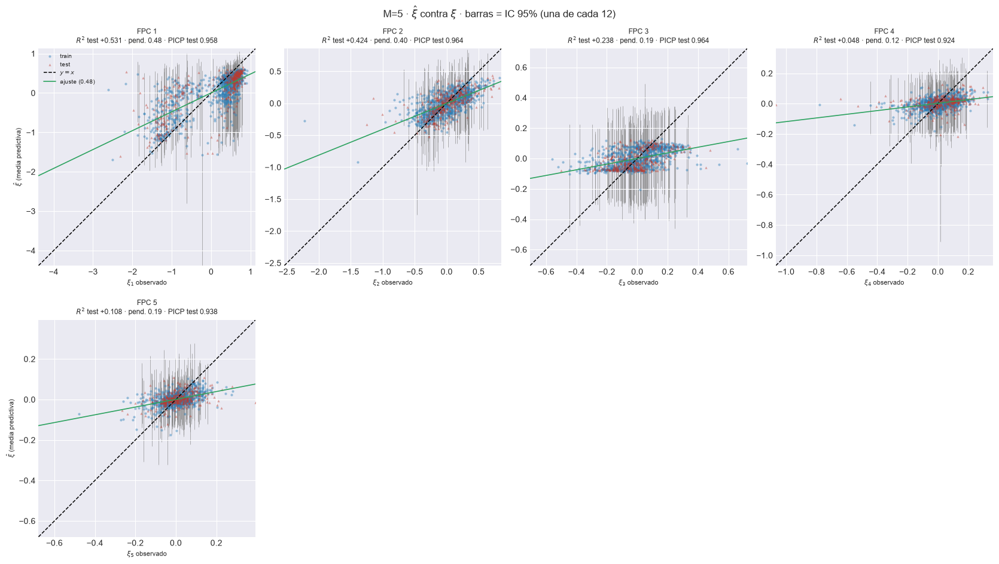

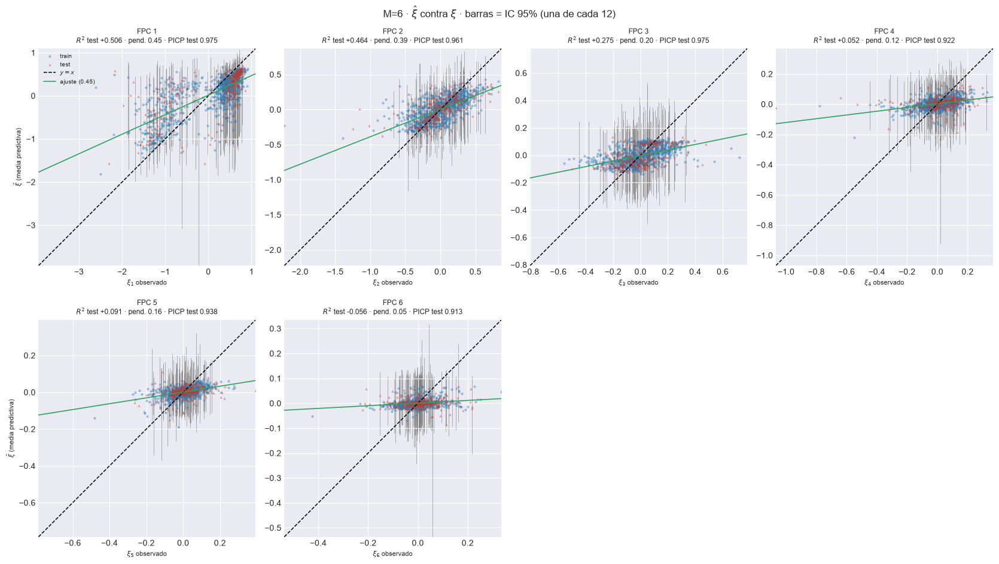

In [18]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()